# Ejercicio 4

Taller de aprendizaje por refuerzo aplicado a algoritmos de ejecución (MIAX, módulo VI).
Material original del taller: A. Oteo García y J. Sanz del Real (`workshop/execution_lab.ipynb`).
Este notebook parte de los ejercicios 2 y 3 (`Ejercicio_2/Ejercicio_2.ipynb`, `Ejercicio_3/Ejercicio_3.ipynb`).

## 0. Planteamiento

El ejercicio es abierto. Se desarrollan dos de las ideas propuestas en el enunciado, porque las dos responden a
problemas que aparecieron en los ejercicios anteriores:

* **Idea B (mejora del Ejercicio 2).** Evitar que el algoritmo deje volumen pendiente y hacer que complete la orden
  hacia el 90 % de su duración, dejando margen. En el Ejercicio 2 el agente usaba el 99 % del tiempo, y varias
  configuraciones (Ejercicios 2 y 3) seguían bien el calendario pero dejaban sin comprar el último título.
* **Idea C (mejora del Ejercicio 3).** Que la duración del entrenamiento dependa del aprendizaje, guardar el mejor
  modelo durante el entrenamiento y poder reanudarlo si se interrumpe. En el Ejercicio 3 el número de episodios era
  fijo y, con los hiperparámetros del Ejercicio 1, 300 episodios no bastaban.

| Sección | Contenido |
|---|---|
| 1-2 | Preparación y bloques reutilizados de los ejercicios 2 y 3 |
| 3 | Idea B: diseño del entorno y comprobaciones previas al entrenamiento |
| 4 | Idea C: parada por aprendizaje, checkpoints y reanudación |
| 5 | Idea B: calibración de la recompensa, agente final y resultados (entrenado con la Idea C) |
| 6 | Conclusiones |

**Marcas de los bloques.** Cada bloque de código va precedido de una etiqueta respecto al Ejercicio 3:
[SIN CAMBIOS], [MODIFICADO] o [NUEVO].

**Datos.** Repsol (`data/rep_data.pkl`). *Train* para entrenar, *validation* para elegir el mejor modelo y decidir
la parada, *test* solo para la comprobación final.

**Configuración.** Hiperparámetros del Ejercicio 2 (γ = 0.95, aprender cada 8 steps, buffer de 20 000, α = 1e-3,
32 neuronas) y exploración adaptativa del Ejercicio 3, salvo en las pruebas de estrés.

**Tiempo de ejecución.** Alrededor de hora y media en CPU.

**Resultados en breve.**

| | Resultado |
|---|---|
| Idea B, diseño | Calendario objetivo que termina en el 90 % del episodio y `−λ` por título pendiente al agotarse el tiempo. El óptimo exacto termina en el ≈ 89 % sin volumen pendiente, para cualquier `λ` |
| Idea B, calibración | `λ ≤ 100` equivalentes y `λ = 1000` desestabiliza el entrenamiento; se elige `λ = 10`. Entrenar con arranques retrasados es lo que hace robusto al agente cuando va por detrás |
| Idea B, agente final (*test*) | 100 % de órdenes completas, 89.2 % del tiempo, error de calendario 0.55 %. Con arranque retrasado completa el 100 %; el agente del Ejercicio 3, el 0 % |
| Idea C | Parada en 140-230 episodios según la semilla (antes, 200 fijos). Con hiperparámetros malos para por estancamiento y conserva el mejor modelo. Reanudar desde un checkpoint da exactamente el mismo resultado que no interrumpir |

### Registro de cambios respecto al Ejercicio 3

| Bloque | Tipo | Cambio | Motivo |
|---|---|---|---|
| 1. Imports | MODIFICADO | Semilla con `keras.utils.set_random_seed` | Entrenamientos reproducibles; necesario para comprobar la reanudación |
| 1. Carga de datos | SIN CAMBIOS | | |
| 2. Entorno, métricas, agente, progreso, ε, `train_agent` | SIN CAMBIOS | Copiados del Ejercicio 3 sin las celdas de verificación | Son la base del ejercicio |
| 3.1 `BestExecutionEnvB`, `TWAPB`, métricas | NUEVO | Calendario que termina en el 90 % del episodio y penalización `λ` por volumen pendiente | Idea B |
| 3.2-3.4 | NUEVO | Equivalencia con el Ejercicio 2, programación dinámica y políticas de referencia | Comprobar el diseño antes de entrenar |
| 4.1 `ProgressMonitorB`, checkpoints, `train_agent_c` | NUEVO | Mejor modelo según validación, parada por aprendizaje, guardado y reanudación | Idea C |
| 4.2-4.5 | NUEVO | Equivalencia con el Ejercicio 3, fallo simulado y reanudación, parada con tres semillas, prueba de estrés, carga de un modelo guardado | Demostrar la Idea C |
| 5 | NUEVO | Calibración de `λ` y del arranque retrasado, agente final y resultados | Idea B |

## 1. Preparación

[MODIFICADO] Imports y semilla. Es la celda del Ejercicio 3 con un cambio: la semilla se fija con
`keras.utils.set_random_seed`. Con Keras 3, `tf.random.set_seed` no controla la inicialización de los pesos, y dos
entrenamientos con la misma semilla no salían iguales. Sin esto no se puede comprobar que reanudar un entrenamiento
desde un checkpoint da el mismo resultado que no interrumpirlo (sección 4).

In [1]:
import os
# Solo cosmético, y debe ir ANTES de importar TensorFlow: silencia los avisos informativos de oneDNN/TF.
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import pickle
import random
import sys
import warnings
from pathlib import Path
from typing import Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Aviso de numpy al deserializar los .pkl antiguos (numpy.core -> numpy._core). Es inocuo.
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Localiza la raíz del repo (la carpeta que contiene src/ y data/) esté donde esté el notebook.
#    Sustituye al `sys.path.append("..")` comentado del original y evita depender del directorio de trabajo.
def find_repo_root() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        for cand in (p, p / "best-execution"):
            if (cand / "src" / "agents" / "dqn.py").exists():
                return cand
    raise FileNotFoundError("No se encuentra la raíz del repo (carpeta con src/agents/dqn.py)")

REPO_ROOT = find_repo_root()
sys.path.append(str(REPO_ROOT))

from src.agents.dqn import DDQNAgent
from src.report.report import plot_results

# Reproducibilidad
import tensorflow as tf
import keras
SEED = 42
keras.utils.set_random_seed(SEED)   # [MODIFICADO] fija random, numpy, tensorflow y keras
tf.get_logger().setLevel("ERROR")   # cosmético: sin el aviso de «GPU no disponible en Windows nativo»

print(f"Raíz del repo : {REPO_ROOT}")
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | TensorFlow {tf.__version__}")

Raíz del repo : C:\Users\gonde\Desktop\TALLER_APLICACION_RL\best-execution
Python 3.13.7 | numpy 2.3.5 | pandas 2.3.3 | TensorFlow 2.21.0


[SIN CAMBIOS] Carga de datos (Repsol).

In [2]:
# Datos disponibles: san_data.pkl y rep_data.pkl
# Carga compatible con pandas 1.x y 2.x
from pandas._libs.internals import BlockPlacement
import pandas.core.internals.blocks as pd_blocks


class _CompatUnpickler(pickle.Unpickler):
    """Deserializa .pkl creados con pandas 1.x en pandas >= 2.1."""

    def find_class(self, module, name):
        if module == "pandas.core.internals.blocks" and name == "new_block":
            def _new_block(values, placement, ndim=None, *args, **kwargs):
                if not isinstance(placement, BlockPlacement):
                    placement = BlockPlacement(placement)
                return pd_blocks.new_block(values, placement, ndim=ndim, *args, **kwargs)
            return _new_block
        return super().find_class(module, name)


def load_pickle_compat(path):
    try:
        with open(path, "rb") as f:
            return pickle.load(f)                   # camino normal (el del original)
    except TypeError:
        with open(path, "rb") as f:
            return _CompatUnpickler(f).load()       # fallback para pandas >= 2.1


dict_ = load_pickle_compat(REPO_ROOT / "data" / "rep_data.pkl")
print({k: len(v) for k, v in dict_.items()}, 'días por conjunto')

{'train': 60, 'val': 30, 'test': 30} días por conjunto


## 2. Entorno, métricas, agente y exploración de los ejercicios 2 y 3

[SIN CAMBIOS] Se copian sin tocar las piezas necesarias de los ejercicios anteriores: el entorno con el estado
`[time_left, vol_left, lag]` y la recompensa de calendario (Ejercicio 2), las métricas y el TWAP de referencia,
el `FastDDQNAgent`, y la medida de progreso, el controlador de ε y el bucle de entrenamiento del Ejercicio 3.
Las explicaciones de cada bloque están en sus notebooks. Se omiten las celdas de verificación y las tablas de
resultados que ya están allí.

In [3]:
class BestExecutionEnv:

    # El retraso respecto al calendario que ve el agente se recorta a ±5 órdenes hijas (ver observation_builder)
    LAG_CLIP = 5.0

    def __init__(self, data, look_back=60, state_mode="schedule"):  # nuevo argumento state_mode
        """Inicialización de la clase del entorno que simula
        el libro de ordenes.
        ----------------------------------------------------
        Input:
            - data:
                Dataframe con los datos previamente
                agrupados del libro de órdenes.

            - look_back:
                Ventana para la generación de features
                roladas en el instante t=0 del episodio.
                Esta ventana representa el rango máximo para
                la construcción de features.

            - state_mode: (Ejercicio 2)
                "basic":    estado del Ejercicio 1 -> [time_left, vol_left]
                "schedule": basic + retraso respecto al calendario lineal
                            -> [time_left, vol_left, lag]
        ----------------------------------------------------
        Variables Internas:
            - episode_bins:
                Número de bines (steps) del episodio.
            - episode_full_len:
                Es igual a look_back + episode_bins.
            - vol_care:
                Volumen total (en títulos) de la orden care.
            - actions_fn:
                Diccionario con las posibles acciones del agente.
                Las claves acceden a la función que evalúa la acción
                tomada por el agente.
            - n_actions:
                Número de acciones posibles.
            - n_features:
                Número de características de los estados.
            - episode:
                Dataframe que contiene los steps y estados del episodio.
            - episode_full:
                Es el episode añadiendo el look_back antes del comienzo
                del episodio.
            - episode_vwap:
                VWAP de mercado al final del episodio.
            - market_ep_vol:
                Volumen (títulos) ejecutado por el mercado en cada bin del episodio.
            - state_pos:
                Número de step en el que nos encontramos.
            - exec_vol:
                Acumulado de títulos ejecutados por el algoritmo.
            - actions_hist:
                Lista de acciones tomadas por el algoritmo en cada step.
            - market_vwap_hist:
                Lista de VWAP de mercado en cada step.
            - reward_hist:
                Lista de rewards obtenidas en cada step.
            - price_hist:
                Lista de precios ejecutados en cada step.
            - vol_hist:
                Lista de títulos ejecutados en cada step.
        """

        # Fixed params
        self.data = data
        self.look_back = look_back
        assert state_mode in ("basic", "schedule")   # debe fijarse antes de _detect_num_feat()
        self.state_mode = state_mode                 # 
        self.episode_bins = None
        self.episode_full_len = None
        self.vol_care = None

        self.actions_fn = {
            0: self._do_nothing,
            1: self._agg_action,
        }

        self.n_actions = len(self.actions_fn)
        self.n_features = self._detect_num_feat()

        # Data variables
        self.episode = None
        self.episode_full = None

        # Env variables
        self.episode_vwap = None
        self.market_ep_vol = None
        self.state_pos = 0
        self.exec_vol = 0
        self.actions_hist = []
        self.algo_vwap_hist = []
        self.market_vwap_hist = []
        self.reward_hist = []
        self.price_hist = []
        self.vol_hist = []

    def _detect_num_feat(self):
        """Detecta el número de variables del estado.
        Función necesaria para adaptarse automaticamente a los
        cambios en las variables de observation_builder.
        """
        self._reset_env_episode_params()
        self._generate_episode()
        s = self.observation_builder()
        return s.shape[0]

    def _reset_env_episode_params(self):
        """
        Reset del episodio e inicialización de los parámetros.
        Las variables internas vuelven a sus valores originales.
        """
        self.episode_full_len = None
        self.episode = None
        self.episode_full = None
        self.episode_vwap = None
        self.market_ep_vol = None
        self.state_pos = 0
        self.algo_vwap = 0
        self.exec_vol = 0
        self.actions_hist = []
        self.algo_vwap_hist = []
        self.market_vwap_hist = []
        self.reward_hist = []
        self.price_hist = []
        self.vol_hist = []

    def _generate_episode_params(self):
        """(1) Se determinan las características de la orden a ejecutar.
        La orden queda definida por:
         - episode_bins:
             Obtención de un número entero aleatorio [400, 600]
             con una distribución uniforme.
         - vol_care:
             Obtención del porcentaje de steps en el que hay que
             ejecutar una orden para cubrir la orden care.
             vol_care responde a un valor uniforme [0.075, 0.125]
             multiplicado por el número self.episode_bins.
             Lo convertimos a entero.
        """
        # Int aleatorio entre 400 y 600 (ambos incluidos) como un objeto numpy.
        #    np.random.randint excluye el extremo superior -> 601.
        self.episode_bins = np.random.randint(400, 601)
        # Float aleatorio uniforme entre 0.075 y 0.125 (fracción de steps en los que hay que comprar)
        pct_bins = np.random.uniform(0.075, 0.125)
        # Tamaño de la orden CARE en títulos = pct_bins * episode_bins, truncado a int
        #    (órdenes hijas de 1 título -> vol_care = nº de acciones agresivas necesarias)
        self.vol_care = int(pct_bins * self.episode_bins)

        self.episode_full_len = self.episode_bins + self.look_back

        assert self.episode_bins <= 600
        assert self.episode_bins >= 400
        assert self.vol_care <= int(self.episode_bins * 0.125)
        assert self.vol_care >= int(self.episode_bins * 0.075)
        assert isinstance(self.vol_care, int)

    def _generate_episode(self):
        """(2) Obtenemos el día y hora en el que comienza el episodio.
        """
        self._generate_episode_params()

        length_episode = 0
        while length_episode != self.episode_full_len:
            # Selección de un día al azar entre los disponibles (las keys de data son fechas)
            selected_day = np.random.choice(list(self.data.keys()))

            # Extraemos el DataFrame de ese día
            data_day = self.data[selected_day]

            # Hora de inicio aleatoria: una marca temporal cualquiera del índice del día
            init_time = np.random.choice(data_day.index)

            hour_pos = data_day.index.get_loc(init_time)
            initial_position = hour_pos - self.look_back
            final_position = hour_pos + self.episode_bins

            if initial_position < 0:
                continue
            else:
                # episode_full: look_back bins previos + los episode_bins del episodio.
                #    Si final_position se sale del día, el slice queda más corto y el
                #    while vuelve a muestrear (resample) otro día/hora.
                self.episode_full = data_day.iloc[initial_position:final_position]

                # episode: solo los bins del episodio (desde hour_pos)
                self.episode = data_day.iloc[hour_pos:final_position]

                length_episode = self.episode_full.shape[0]


    def reset(self) -> np.array:
        """Reinicialización del episodio junto con los parámetros.
        Devuelve la primera observación del nuevo episodio.
        """
        self._reset_env_episode_params()
        self._generate_episode()
        self._compute_episode_market_feat()

        return self.observation_builder()

    def observation_builder(self) -> np.array:
        """(3) Función para la construcción de las observaciones del estado.
            ------------------------------------------------------------
            Ejercicio 2:
                - Primera característica es tiempo restante en porcentaje.
                - Segunda característica es el volumen restante en porcentaje.
                - Tercera característica (state_mode="schedule"): retraso respecto
                  al calendario lineal, medido en órdenes hijas.
        """
        time_left = (self.episode_bins - self.state_pos) / self.episode_bins
        vol_left = (self.vol_care - self.exec_vol) / self.vol_care
        if self.state_mode == "basic":
            return np.array([time_left, vol_left])

        # Retraso (lag) = títulos que el calendario lineal exige llevar al terminar ESTE step menos los que ya
        #    llevamos comprados. lag > 0: vamos por detrás del calendario · lag < 0: por delante.
        #    Se mide en órdenes hijas (1 título), de modo que no depende del tamaño de la orden ni de la duración
        #    del episodio, y se recorta a ±LAG_CLIP y se escala a [-1, 1]: más allá de ese rango la decisión óptima
        #    ya es obvia (comprar si vamos muy por detrás, esperar si vamos muy por delante).
        lag = self.vol_care * (self.state_pos + 1) / self.episode_bins - self.exec_vol
        lag_feat = float(np.clip(lag / self.LAG_CLIP, -1.0, 1.0))
        obs = np.array([time_left, vol_left, lag_feat])

        return obs

    def _compute_episode_market_feat(self) -> Tuple[float, pd.Series]:
        """(4) Cálculo de los valores VWAP y Market Vol del episodio.
        Como no tenemos las ejecuciones de mercado, asumimos que el
        precio es el mid price de cada step.
        """
        # Mid price de cada bin
        mid = (self.episode["ask1"] + self.episode["bid1"]) / 2
        # Volumen del mercado en cada bin = incremento del volumen acumulado.
        #    Se recorta a 0 por calidad de datos: hay (muy pocos) incrementos negativos
        #    en train (correcciones del volumen acumulado) que no tienen sentido como volumen.
        self.market_ep_vol = self.episode["cumvol"].diff().clip(lower=0)
        self.market_ep_vol.iloc[0] = 0
        # Volumen total negociado por el mercado en el episodio
        cum_vol = self.market_ep_vol.sum()
        # VWAP del episodio: el mid de cada bin t se pondera con el volumen negociado
        #    justo después (bin t+1). .values para que pandas no alinee por índice.
        if cum_vol == 0:
            # Episodio sin ningún volumen de mercado: VWAP indefinido -> usamos el mid medio
            self.episode_vwap = mid.mean()
        else:
            self.episode_vwap = (mid.values[:-1] * self.market_ep_vol.values[1:]).sum() / cum_vol

        return self.episode_vwap, self.market_ep_vol

    def _compute_algo_vwap(self) -> float:
        """(8) Cálculo del VWAP del algoritmo hasta el step actual.
        """
        # VWAP del algoritmo = sum(precio * volumen) / sum(volumen) con lo ejecutado hasta ahora
        p_arr = np.array(self.price_hist)
        v_arr = np.array(self.vol_hist)
        if v_arr.sum() == 0:
            # Todavía no hemos ejecutado nada: el VWAP no está definido
            # (NaN -> stats_df hace ffill y el gráfico no dibuja nada hasta la primera ejecución)
            return np.nan
        algo_vwap = (p_arr * v_arr).sum() / v_arr.sum()
        return algo_vwap

    def _compute_reward(self, price: float, vol: float) -> float:
        """(6) Función de diseño de los rewards y penalizaciones que
        recibe el algoritmo al tomar las acciones.
        --------------------------------------------------------
        Ejercicio 2 (replicar un TWAP):
            - El reward es MENOS el valor absoluto de la desviación, en títulos, entre lo
              ejecutado y el calendario lineal (TWAP) tras la acción. No usa el precio.
        """
        # Calendario lineal: al terminar este step (state_pos todavía no se ha incrementado) el TWAP
        #    llevaría vol_care * (state_pos + 1) / episode_bins títulos. `exec_vol` ya incluye la acción actual.
        #    Un TWAP es un calendario independiente del precio -> `price` y `vol` no intervienen.
        scheduled = self.vol_care * (self.state_pos + 1) / self.episode_bins
        deviation = self.exec_vol - scheduled           # > 0 por delante · < 0 por detrás (en títulos)
        reward = -abs(deviation)
        return reward

    def _compute_stop_conditions(self) -> Tuple[bool, bool]:
        """(10) Define las condiciones de parada del episodio
        Return:
            Tiempo agotado, orden completada
        """
        # Tiempo agotado: ya hemos consumido todos los bins del episodio
        is_bins_complete = self.state_pos >= self.episode_bins
        # Orden completada: ya hemos comprado (al menos) todo el volumen de la orden CARE
        is_ord_complete = self.exec_vol >= self.vol_care
        return is_bins_complete, is_ord_complete

    def _compute_done_reward(self) -> float:
        """(12) Recompensa al terminar el episodio.
        Ejercicio 2: si la orden se completa antes de agotar el tiempo, el calendario "sigue corriendo":
        se carga la desviación que se habría acumulado en los steps que quedan por jugar.
        """
        # Así el coste de un episodio es la suma de |desviación| a lo largo de TODOS sus steps, termine
        #    cuando termine: completar la orden antes de tiempo no sirve para "escapar" de las penalizaciones
        #    (sin este término el óptimo sería terminar unos steps antes que el TWAP, ver §2.5).
        #    state_pos ya se ha incrementado: los steps sin jugar son state_pos, ..., episode_bins - 1.
        #    Si el tiempo se ha agotado la lista está vacía y la recompensa final vale 0.
        remaining = np.arange(self.state_pos, self.episode_bins)
        scheduled = self.vol_care * (remaining + 1) / self.episode_bins
        done_reward = -float(np.sum(np.abs(self.exec_vol - scheduled)))
        return done_reward

    def _agg_action(self) -> float:
        """(7) Acción agresiva de compra de un título a precio de episode['ask1'].
        Devolvemos el reward asociado a esa acción.
        """
        # Precio de la acción agresiva: ask1 del bin actual (acceso posicional por state_pos)
        price = self.episode["ask1"].iloc[self.state_pos]
        # Registramos precio y volumen (1 título) y actualizamos el volumen ejecutado
        self.price_hist.append(price)
        vol = 1
        self.exec_vol += vol
        self.vol_hist.append(vol)

        # VWAP del algoritmo tras esta ejecución, guardado en su histórico
        algo_vwap = self._compute_algo_vwap()
        self.algo_vwap_hist.append(algo_vwap)
        # Reward asociado a esta ejecución
        reward = self._compute_reward(price, vol)
        return reward

    def _do_nothing(self) -> float:
        """(9) No hacer nada y devolvemos el reward asociado a la acción
        """
        # Mismo proceso que _agg_action pero con precio y volumen ejecutado = 0
        price = 0
        vol = 0
        self.price_hist.append(price)
        self.vol_hist.append(vol)
        algo_vwap = self._compute_algo_vwap()
        self.algo_vwap_hist.append(algo_vwap)
        reward = self._compute_reward(price, vol)

        return reward

    def _compute_market_vwap(self) -> float:
        """(5) Cálculo del VWAP del mercado hasta el step actual.
        """
        # Mismo criterio que en _compute_episode_market_feat: precio = mid de cada step...
        mid_p = (self.episode["ask1"] + self.episode["bid1"]) / 2
        mkt_p = mid_p
        # ...y volumen = el negociado en el bin siguiente (shift(-1)). El último step no tiene
        # bin siguiente -> fillna(0) (si no, el NaN contaminaría todas las sumas).
        v = self.market_ep_vol.shift(-1).fillna(0)
        # VWAP del mercado acumulado hasta el step actual (incluido)
        p_arr = mkt_p.values[:self.state_pos + 1]
        v_arr = v.values[:self.state_pos + 1]
        sum_vol = v_arr.sum()
        # Si el mkt vol hasta el step == 0, devolvemos el último precio hasta el step
        if sum_vol == 0:
            return p_arr[-1]
        # VWAP acumulado hasta el step
        market_vwap = (p_arr * v_arr).sum() / sum_vol
        return market_vwap

    def _compute_done(self) -> bool:
        """(11) Reglas de finalización del episodio.
        """
        # Terminamos si se agota el tiempo o si se completa la orden (cualquiera de las dos)
        conditions = self._compute_stop_conditions()
        is_bins_complete, is_ord_complete = conditions
        done = is_bins_complete or is_ord_complete
        return done

    def step(self, action) -> Tuple[np.array, float, bool, dict]:
        """ Evalúa la acción, calcula la recompensa, devuelve el
        nuevo estado y si el episodio ha terminado.
        """
        market_vwap = self._compute_market_vwap()

        act_fn = self.actions_fn.get(action)
        if act_fn is None:
            raise ValueError(
                f"Invalid action {action}. Valid actions {self.actions_fn.keys()}"
            )

        reward = act_fn()

        # Guardamos la acción tomada (actions_hist estaba documentada pero nunca se rellenaba)
        self.actions_hist.append(action)
        self.market_vwap_hist.append(market_vwap)
        self.reward_hist.append(reward)

        self.state_pos += 1

        done = self._compute_done()

        if done:
            done_reward = self._compute_done_reward()
            reward += done_reward
            self.reward_hist[-1] += done_reward   # reward_hist recoge así el retorno completo del episodio
            return None, reward, done, {}

        observation = self.observation_builder()

        return np.array(observation), reward, done, {}

    def action_sample(self) -> int:
        """(13) Devuelve una acción aleatoria. El valor ha de corresponder
        con las keys de actions_fn.
        """
        # Política aleatoria SESGADA hacia no hacer nada: comprar con probabilidad p igual a
        #    la participación que necesita la orden (vol_care / episode_bins ~ 7.5%-12.5%).
        #    Con p = 0.5 la orden se completaría en ~2*vol_care steps (~20% del episodio) y el
        #    buffer solo contendría estados con mucho tiempo restante; con p ~ vol_care/bins el
        #    comportamiento aleatorio recorre todo el episodio (time_left de 1 a 0).
        p = self.vol_care / self.episode_bins
        action = np.random.choice([0, 1], p=[1-p, p])
        return action

    def stats_df(self):
        """Información para el gráfico de resultados de la ejecución
        """

        my_df = pd.DataFrame(
            {"vwap": self.algo_vwap_hist, "vol": self.vol_hist},
            index=list(self.episode.index)[:len(self.algo_vwap_hist)]
        )
        my_df = my_df.reindex(self.episode.index)
        my_df["vol"] = my_df["vol"].fillna(0)
        my_df["vwap"] = my_df["vwap"].ffill()


        p = self.episode["ask1"]
        v = self.episode["cumvol"].diff().shift(-1)
        last_v = self.episode_full["cumvol"].diff().iloc[-1]
        v.iloc[-1] = last_v
        market_vwap = (p * v).cumsum() / v.cumsum()
        market_df = pd.DataFrame(
            {"vwap": market_vwap, "vol": v},
            index=v.index
        )

        mpx = (self.episode["ask1"] + self.episode["bid1"]) / 2

        return my_df, market_df, mpx

In [4]:
def episode_metrics(env) -> dict:
    """Métricas de un episodio TERMINADO (se llamó a env.step hasta done).
    slippage_bps = (VWAP algo - VWAP mercado) / VWAP mercado * 1e4  ->  en una compra, negativo = mejor que el mercado.
    Nuevas (fidelidad al calendario lineal de un TWAP):
        mae_pct : error de seguimiento medio |ejecutado - calendario| en % de la orden        (criterio C3)
        max_dev : desvío máximo respecto al calendario, en títulos
        gap_cv  : coeficiente de variación de la separación entre compras consecutivas        (criterio C4)
    """
    prices = np.array(env.price_hist, dtype=float)
    vols = np.array(env.vol_hist, dtype=float)
    exec_vol = vols.sum()
    algo_vwap = (prices * vols).sum() / exec_vol if exec_vol > 0 else np.nan
    B, C, steps = env.episode_bins, env.vol_care, env.state_pos
    dev = np.cumsum(vols) - C * np.arange(1, steps + 1) / B          # desviación respecto al calendario tras cada step
    gaps = np.diff(np.flatnonzero(env.actions_hist))                 # separación entre compras (en steps)
    return {
        "bins": B, "vol_care": C, "steps": steps,
        "exec_frac": exec_vol / C, "time_frac": steps / B,
        "algo_vwap": algo_vwap, "mkt_vwap": env.episode_vwap,
        "slippage_bps": (algo_vwap - env.episode_vwap) / env.episode_vwap * 1e4,
        "sum_reward": float(np.sum(env.reward_hist)),
        "mae_pct": float(np.abs(dev).mean() / C * 100),              # 
        "max_dev": float(np.abs(dev).max()),                         # 
        "gap_cv": float(gaps.std() / gaps.mean()) if len(gaps) > 2 else np.nan,   # 
    }


class TWAP(DDQNAgent):
    def act(self, s): # [T, V, lag]
        # TWAP determinista a partir del estado: calendario lineal (ver Ejercicio 1).
        # Compramos siempre que vayamos igual o por detrás de ese calendario, es decir, cuando V >= T.
        T, V = s[0], s[1]       # el estado ahora tiene 3 variables; solo se usan las dos primeras
        a = int(V >= T - 1e-9)
        return a


def run_episode(env, policy):
    s, done = env.reset(), False
    while not done:
        s, r, done, _ = env.step(policy(s))
    return episode_metrics(env)


def evaluate(env, policy, n_episodes=40, seed0=10_000):
    rows = []
    for i in range(n_episodes):
        np.random.seed(seed0 + i)       # mismo episodio para todas las políticas
        rows.append(run_episode(env, policy))
    return pd.DataFrame(rows)


def summarize(df):
    # Una fila por criterio de §2.1 (C1–C5) más el retorno
    return pd.Series({
        "C1 · órdenes completas (%)": (df.exec_frac >= 1).mean() * 100,
        "volumen ejecutado (% de la orden)": df.exec_frac.mean() * 100,
        "C2 · tiempo usado (% del episodio)": df.time_frac.mean() * 100,
        "C3 · error de seguimiento (% de la orden)": df.mae_pct.mean(),
        "desvío máximo (títulos)": df.max_dev.mean(),
        "C4 · CV de la separación entre compras": df.gap_cv.mean(),
        "C5 · slippage vs VWAP (bps) · media": df.slippage_bps.mean(),
        "retorno (suma de rewards) · media": df.sum_reward.mean(),
    })


N_EVAL = 40     # episodios por evaluación (los mismos para todas las políticas)

In [5]:
import time


class FastDDQNAgent(DDQNAgent):
    """Double DQN idéntico a DDQNAgent, con inferencia en numpy y paso de gradiente compilado (≈ 4× más rápido por learn)."""

    def __init__(self, *args, **kwargs):
        self._w = None                                   # pesos de la red primary cacheados para la inferencia
        super().__init__(*args, **kwargs)
        model, optimizer = self.primary_model, self.primary_model.optimizer

        @tf.function(reduce_retracing=True)
        def _train_step(x, y):                           # mismo MSE y mismo Adam que train_on_batch
            with tf.GradientTape() as tape:
                loss = tf.reduce_mean(tf.square(y - model(x, training=True)))
            grads = tape.gradient(loss, model.trainable_variables)
            optimizer.apply_gradients(zip(grads, model.trainable_variables))
            return loss
        self._train_step = _train_step

    @staticmethod
    def _forward(weights, x):                            # Dense(relu) -> Dense(relu) -> Dense(linear), en numpy
        W1, b1, W2, b2, W3, b3 = weights
        h = np.maximum(x @ W1 + b1, 0)
        h = np.maximum(h @ W2 + b2, 0)
        return h @ W3 + b3

    def _act_no_explore(self, s):
        if self._w is None:
            self._w = self.primary_model.get_weights()
        return int(np.argmax(self._forward(self._w, s)))

    def learn(self):
        batch = self.sample()                            # CER, igual que el original
        s_list = np.array([e[0].tolist() for e in batch], dtype=np.float32)
        s1_list = np.array([e[3].tolist() for e in batch if e[3] is not None], dtype=np.float32)
        w_primary, w_target = self.primary_model.get_weights(), self.target_model.get_weights()
        targets = self._forward(w_primary, s_list)
        qs1 = self._forward(w_primary, s1_list)          # la primary ELIGE la mejor acción siguiente...
        q_target = self._forward(w_target, s1_list)      # ...y la target la EVALÚA (Double DQN)
        k = 0
        for i, (s, a, r, s1) in enumerate(batch):
            if s1 is None:
                targets[i][a] = r
            else:
                targets[i][a] = r + self.gamma * q_target[k, np.argmax(qs1[k])]
                k += 1
        loss = float(self._train_step(s_list, targets.astype(np.float32)))   # pérdida REAL del batch
        self._w = None                                   # los pesos han cambiado: invalidar la caché
        return loss

In [6]:
from contextlib import contextmanager


@contextmanager
def preserve_rng():
    """Guarda y restaura el estado del generador de numpy.
    Medir el progreso NO debe alterar la aleatoriedad del entrenamiento (episodios, exploración, muestreo del buffer):
    así, con el ε lineal, el entrenamiento es exactamente el mismo con o sin mediciones."""
    state = np.random.get_state()
    try:
        yield
    finally:
        np.random.set_state(state)


class ProgressMonitor:
    """¿Cuánto ha mejorado el agente? Evaluación greedy sobre un conjunto FIJO de episodios de control.

    progreso por episodio  p_i = log(coste_aleatoria_i / coste_agente_i) / log(coste_aleatoria_i / coste_TWAP_i)
        · coste = −retorno = desviación acumulada respecto al calendario (en títulos·step)
        · p = 0 -> el agente no es mejor que actuar al azar  ·  p = 1 -> el agente iguala al benchmark clásico (TWAP)
        · se recorta a [0, 1]; si el episodio no completa la orden, p_i se limita a p_cap
    progreso del agente    p = media de p_i en los episodios de control
    """

    def __init__(self, data, n_control=8, seed0=50_000, state_mode="schedule", p_cap_incomplete=0.8):
        self.env = BestExecutionEnv(data, 60, state_mode=state_mode)
        self.seeds = [seed0 + i for i in range(n_control)]
        self.p_cap = p_cap_incomplete
        # Anclas (se calculan UNA vez, sobre los mismos episodios de control)
        self.ref_random = self.run_policy(lambda s: self.env.action_sample())   # nivel 0: aleatoria (exploración pura)
        self.ref_bench = self.run_policy(TWAP(self.env).act)                    # nivel 1: TWAP clásico del Ejercicio 1
        self.cost_rand = -self.ref_random.sum_reward.values
        self.cost_bench = -self.ref_bench.sum_reward.values
        assert (self.cost_rand > self.cost_bench).all(), "el benchmark debe ser mejor que la aleatoria en todos los episodios"

    def run_policy(self, policy):
        rows = []
        with preserve_rng():                       # no tocar la aleatoriedad del entrenamiento
            for sd in self.seeds:
                np.random.seed(sd)                 # mismo episodio (día, hora, B, C) en cada medición
                s, done = self.env.reset(), False
                while not done:
                    s, r, done, _ = self.env.step(policy(s))
                rows.append(episode_metrics(self.env))
        return pd.DataFrame(rows)

    def progress(self, df, clip=True):
        cost = np.maximum(-df.sum_reward.values, 1e-9)
        p = np.log(self.cost_rand / cost) / np.log(self.cost_rand / self.cost_bench)
        if clip:
            p = np.clip(p, 0.0, 1.0)
            p = np.where(df.exec_frac.values >= 1, p, np.minimum(p, self.p_cap))   # orden incompleta -> p <= p_cap
        return p

    def measure(self, agent):
        """Evalúa el agente greedy (sin exploración ni aprendizaje) y devuelve (progreso, métricas por episodio)."""
        prev_env, prev_train = agent.env, agent._trainable
        agent.env, agent._trainable = self.env, False        # el agente debe consultar el entorno que ejecuta (step 0)
        try:
            df = self.run_policy(agent.act)
        finally:
            agent.env, agent._trainable = prev_env, prev_train
        return float(self.progress(df).mean()), df

In [7]:
class AdaptiveEpsilon:
    """Traduce el progreso medido (p ∈ [0, 1]) en un ε.

    objetivo     ε*(p) = ε_min + (ε_max − ε_min) · (1 − p)        (lineal en el PROGRESO, no en los episodios)
    suavizado    ε ← ε + β · (ε* − ε),   β = beta_down si ε* < ε (bajar)  ·  beta_up si ε* > ε (subir, más prudente)
    """

    def __init__(self, eps_max=1.0, eps_min=0.05, beta_down=0.5, beta_up=0.2):
        self.eps_max, self.eps_min = eps_max, eps_min
        self.beta_down, self.beta_up = beta_down, beta_up
        self.eps = eps_max

    def target(self, p):
        return self.eps_min + (self.eps_max - self.eps_min) * (1.0 - float(np.clip(p, 0, 1)))

    def update(self, p):
        tgt = self.target(p)
        beta = self.beta_down if tgt < self.eps else self.beta_up
        self.eps = float(np.clip(self.eps + beta * (tgt - self.eps), self.eps_min, self.eps_max))
        return self.eps

In [8]:
DEFAULT_CFG = dict(               # valores por defecto = los del Ejercicio 1
    nepisodes=300, epsilon=1.0, min_epsilon=0.05, gamma=0.99, alpha=1e-3, buffer_size=50_000,
    batch_size=64, hidden_neurons=32, learn_after=64, update_target_mult=10,    # update_target_after = mult * learn_after
    state_mode="schedule", seed=42,
    # Ejercicio 3: política de exploración
    eps_schedule="adaptive",      # "linear" = la del Ejercicio 2 (depende del nº de episodios) · "adaptive" = depende del progreso
    eval_every=10,                # cada cuántos episodios se MIDE el progreso (frecuencia de medida; no fija el valor de ε)
    n_control=8,                  # episodios de control de la medida de progreso
    beta_down=0.5, beta_up=0.2,   # suavizado del controlador (bajar / subir ε)
    p_cap_incomplete=0.8,         # progreso máximo de un episodio de control que no completa la orden
)

# Configuración final del Ejercicio 2 (§3.4 de su notebook): no se toca ningún hiperparámetro salvo la exploración
CFG_EJ2 = dict(nepisodes=200, gamma=0.95, alpha=1e-3, buffer_size=20_000, batch_size=64,
               hidden_neurons=32, learn_after=8, update_target_mult=10)


def train_agent(cfg, split="train", n_log=20, verbose=True):
    c = {**DEFAULT_CFG, **cfg}
    learn_after = c["learn_after"]
    update_target_after = c["update_target_mult"] * learn_after
    adaptive = c["eps_schedule"] == "adaptive"                                          # 
    epsilon_decay = (c["epsilon"] - c["min_epsilon"]) / (0.8 * c["nepisodes"])      # solo se usa con el esquema lineal
    np.random.seed(c["seed"]); tf.random.set_seed(c["seed"])
    env = BestExecutionEnv(dict_[split], 60, state_mode=c["state_mode"])
    agent = FastDDQNAgent(env, gamma=c["gamma"], epsilon=c["epsilon"], alpha=c["alpha"], batch_size=c["batch_size"],
                          buffer_size=c["buffer_size"], hidden_neurons=c["hidden_neurons"])
    # Medida de progreso (también con el esquema lineal, solo como diagnóstico: allí no modifica ε)
    monitor = ProgressMonitor(dict_[split], n_control=c["n_control"], state_mode=c["state_mode"],
                              p_cap_incomplete=c["p_cap_incomplete"])
    eps_ctrl = AdaptiveEpsilon(c["epsilon"], c["min_epsilon"], c["beta_down"], c["beta_up"])     # 
    t0 = time.perf_counter()

    # (1) Relleno del buffer. En este punto epsilon es 1 -> actuando random
    s = env.reset()
    for _ in range(c["buffer_size"]):
        a = agent.act(s)
        s1, r, done, _ = env.step(a)
        agent.experience(s, a, r, s1, done)
        s = s1
        if done:
            s = env.reset()

    # (2) Entrenamiento
    agent.set_trainable(True)
    learn_counter, history = 0, []
    for episode in range(c["nepisodes"]):
        s = env.reset()
        step, cum_reward, ep_losses = 0, 0.0, []
        eps_used = agent.epsilon                                      # ε con el que se juega este episodio
        while True:
            a = agent.act(s)                                          # ε-greedy
            s1, r, done, _ = env.step(a)                              # el entorno evalúa la acción
            agent.experience(s, a, r, s1, done)                       # transición al buffer
            learn_counter += 1
            cum_reward += r
            s = s1
            step += 1
            if not learn_counter % learn_after:
                ep_losses.append(agent.learn())                       # un paso de gradiente con un batch del buffer
            if not learn_counter % update_target_after:
                agent.update_target()                                 # primary -> target
            if done:
                m = episode_metrics(env)
                m.update(episode=episode, ret=cum_reward, loss=np.mean(ep_losses) if ep_losses else np.nan, epsilon=eps_used)
                # Actualización de ε
                if not adaptive:                                      # Ejercicio 2: depende del nº de episodios
                    agent.epsilon = max(agent.epsilon - epsilon_decay, c["min_epsilon"])
                if not (episode + 1) % c["eval_every"]:              # medida del progreso (greedy, episodios de control)
                    prog, ctrl_df = monitor.measure(agent)
                    if adaptive:                                      # Ejercicio 3: ε depende del progreso medido
                        agent.epsilon = eps_ctrl.update(prog)
                    m.update(progress=prog, ctrl_mae=ctrl_df.mae_pct.mean(),
                             ctrl_complete=(ctrl_df.exec_frac >= 1).mean() * 100, ctrl_ret=ctrl_df.sum_reward.mean())
                history.append(m)
                if verbose and not (episode + 1) % n_log:
                    h = pd.DataFrame(history[-n_log:])
                    print(f"Episode: {episode + 1:>3}, rew: {h.ret.mean():8.1f}, error calendario (train, con ε): {h.mae_pct.mean():5.2f}% | "
                          f"control greedy: progreso {h.progress.dropna().iloc[-1]:.2f}, error {h.ctrl_mae.dropna().iloc[-1]:5.2f}%, "
                          f"completas {h.ctrl_complete.dropna().iloc[-1]:3.0f}% | ε siguiente: {agent.epsilon:.3f}")
                break
    hist = pd.DataFrame(history)
    for col in ("progress", "ctrl_mae", "ctrl_complete", "ctrl_ret"):
        if col not in hist:
            hist[col] = np.nan
    return agent, hist, {"cfg": c, "seconds": time.perf_counter() - t0, "monitor": monitor}


def evaluate_agent(agent, split="val", n_episodes=N_EVAL, seed0=10_000):
    """Evaluación greedy (sin exploración ni aprendizaje) sobre episodios fijados por semilla."""
    eval_env = BestExecutionEnv(dict_[split], 60, state_mode=agent.env.state_mode)
    agent.set_trainable(False)
    agent.env = eval_env                       # el agente debe consultar el entorno que realmente ejecuta (ver Ejercicio 1)
    return evaluate(eval_env, agent.act, n_episodes=n_episodes, seed0=seed0)


def run_summary(hist, info):
    """Resumen de un entrenamiento: cuándo alcanza el objetivo y cuánta exploración ha consumido."""
    meas = hist.dropna(subset=["progress"])
    ok = meas[(meas.ctrl_complete == 100) & (meas.ctrl_mae < 1.0)]
    low = hist.epsilon <= 0.10
    return {
        "1er episodio con objetivo cumplido (control)": int(ok.episode.iloc[0]) + 1 if len(ok) else np.nan,
        "1er episodio con ε ≤ 0.10": int(hist.episode[low].iloc[0]) + 1 if low.any() else np.nan,
        "acciones aleatorias (% de los steps)": float((hist.epsilon * hist.steps).sum() / hist.steps.sum() * 100),
        "progreso final (control)": float(meas.progress.iloc[-1]),
        "entrenamiento (s)": info["seconds"],
    }


def plot_training(hist, title="", others=None):
    """Curvas del Ejercicio 3: ε frente al progreso, error greedy de control, retorno y pérdida.
    others: {nombre: hist} de otros entrenamientos para superponer (p. ej. el ε lineal)."""
    W = 15
    roll = lambda x: pd.Series(x).rolling(W, min_periods=1).mean()
    runs = {"adaptativo": hist, **(others or {})}
    styles = ["-", "--", ":"]
    fig, ax = plt.subplots(2, 2, figsize=(15, 8))
    for (name, h), ls in zip(runs.items(), styles):
        meas = h.dropna(subset=["progress"])
        ax[0, 0].plot(h.episode + 1, h.epsilon, color="tab:purple", ls=ls, label=f"ε · {name}")
        ax[0, 0].plot(meas.episode + 1, meas.progress, marker="o", color="tab:green", ms=3, ls=ls, lw=0.8, label=f"progreso p · {name}")
        ax[0, 1].plot(meas.episode + 1, meas.ctrl_mae, marker="o", color="tab:red", ms=3, ls=ls, lw=0.8, label=name)
        ax[1, 0].plot(h.episode + 1, roll(h.ret), color="tab:blue", ls=ls, label=name)
        ax[1, 1].plot(h.episode + 1, roll(h.loss), color="tab:brown", ls=ls, label=name)
    ax[0, 0].set_title("ε aplicado y progreso medido"); ax[0, 0].set_ylim(-0.03, 1.03)
    ax[0, 1].set_yscale("log"); ax[0, 1].axhline(1.0, color="k", ls=":", lw=1, label="objetivo < 1 %")
    ax[0, 1].axhline(0.5, color="gray", ls=":", lw=1, label="≈ mínimo teórico")
    ax[0, 1].set_title("Error de calendario greedy en los episodios de control (%, log)")
    ax[1, 0].set_title(f"Retorno por episodio de entrenamiento (con exploración, media móvil {W})")
    ax[1, 1].set_yscale("log"); ax[1, 1].set_title("Pérdida (MSE real del batch, log)")
    for a_ in ax.ravel():
        a_.grid(True); a_.set_xlabel("episodio"); a_.legend(fontsize=7)
    fig.suptitle(title); plt.tight_layout(); plt.show()


def plot_gallery(env, named_policies, seeds):
    """Para cada semilla (= un episodio distinto): volumen acumulado (% de la orden) y desviación respecto al calendario."""
    fig, ax = plt.subplots(2, len(seeds), figsize=(5.2 * len(seeds), 7), squeeze=False)
    for j, seed in enumerate(seeds):
        for name, (pol, color) in named_policies.items():
            np.random.seed(seed)
            s, done = env.reset(), False
            while not done:
                s, r, done, _ = env.step(pol(s))
            B, C, n = env.episode_bins, env.vol_care, env.state_pos
            x = np.arange(1, n + 1) / B * 100
            ejec = np.cumsum(env.vol_hist)
            ax[0, j].step(x, ejec / C * 100, where="post", color=color, label=name, lw=1.4)
            ax[1, j].plot(x, ejec - C * np.arange(1, n + 1) / B, color=color, label=name, lw=0.9)
        ax[0, j].plot([0, 100], [0, 100], "k:", label="calendario lineal")
        ini = env.episode.index[0]
        ax[0, j].set_title(f"{ini:%Y-%m-%d %H:%M} · B={B}, C={C}", fontsize=10)
        ax[1, j].axhline(0, color="k", ls=":"); ax[1, j].set_xlabel("% del tiempo del episodio")
    ax[0, 0].set_ylabel("% de la orden ejecutado"); ax[1, 0].set_ylabel("desviación (títulos)")
    ax[0, 0].legend(fontsize=8); ax[1, 0].legend(fontsize=8)
    for a_ in ax.ravel():
        a_.grid(True)
    plt.tight_layout(); plt.show()

---
## 3. Idea B: no dejar volumen pendiente y terminar hacia el 90 % del tiempo

### 3.1 Diseño

En el Ejercicio 2 el agente completa la orden usando el 99 % del episodio: no deja margen, y si se retrasa al final
no tiene tiempo de recuperarse. Además, en los barridos de hiperparámetros del Ejercicio 2 y en la prueba de estrés
del Ejercicio 3 aparecía siempre el mismo fallo: el agente seguía bien el calendario pero no compraba el último
título. La recompensa del Ejercicio 2 apenas castiga ese caso, porque el calendario solo exige el último título en el
último step.

Cambios en el entorno (`BestExecutionEnvB`, subclase del entorno del Ejercicio 2):

| | Ejercicio 2 | Idea B |
|---|---|---|
| Calendario objetivo tras `k` steps | `C·k/B` | `S(k) = min(C·k/T*, C)`, con `T* = ρ·B` y `ρ = 0.9` |
| Estado | `[time_left, vol_left, lag]` | igual; `lag` se mide respecto a `S` |
| Recompensa por step | `−|e − C·(t+1)/B|` | `−|e − S(t+1)|` |
| Recompensa final (orden completa antes de tiempo) | desviación del resto del episodio | igual con `S`; después de `T*` vale 0 |
| Recompensa final (tiempo agotado con volumen pendiente) | 0 | `−λ · títulos pendientes` |

Por qué se hace así:

* Terminar hacia el 90 % se consigue desplazando el calendario, no con un premio aparte por terminar pronto. Así la
  recompensa sigue siendo una sola señal en títulos, con la misma escala que en el Ejercicio 2, y no hay que
  equilibrar dos objetivos.
* En el margen (`t > T*`) el calendario ya exige la orden completa, así que cada step con volumen pendiente cuesta
  tantos puntos como títulos falten. El último título deja de ser un caso que solo se castiga en el step final.
* `λ` castiga explícitamente acabar con volumen pendiente. Su valor se calibra en la sección 5.
* Con `ρ = 1` y `λ = 0` el entorno es exactamente el del Ejercicio 2 (se comprueba en 3.2).

[NUEVO] `BestExecutionEnvB`, el TWAP con el calendario al 90 % (`TWAPB`, que generaliza el TWAP del Ejercicio 1) y
las métricas medidas respecto al nuevo calendario. `episode_metrics_b` añade el volumen pendiente, y `summarize_b`
resume los criterios del Ejercicio 2 cambiando el objetivo de tiempo usado (≈ 90 %).

In [9]:
class BestExecutionEnvB(BestExecutionEnv):
    """Entorno del Ejercicio 2 con el calendario terminando en T* = target_frac * B y una penalización
    pending_penalty (lambda) por título pendiente si el episodio acaba por tiempo.
    Con target_frac = 1 y pending_penalty = 0 es el entorno del Ejercicio 2."""

    def __init__(self, data, look_back=60, state_mode="schedule", target_frac=0.9, pending_penalty=0.0):
        assert 0 < target_frac <= 1 and pending_penalty >= 0
        self.target_frac = float(target_frac)        # antes de super().__init__, que ya construye una observación
        self.pending_penalty = float(pending_penalty)
        super().__init__(data, look_back, state_mode)

    def scheduled(self, k):
        """Títulos que el calendario exige tras k steps: min(C * k / T*, C)."""
        T_star = self.target_frac * self.episode_bins
        return np.minimum(self.vol_care * np.asarray(k, dtype=float) / T_star, self.vol_care)

    def observation_builder(self) -> np.array:
        time_left = (self.episode_bins - self.state_pos) / self.episode_bins
        vol_left = (self.vol_care - self.exec_vol) / self.vol_care
        if self.state_mode == "basic":
            return np.array([time_left, vol_left])
        lag = float(self.scheduled(self.state_pos + 1)) - self.exec_vol      # retraso respecto al nuevo calendario
        return np.array([time_left, vol_left, float(np.clip(lag / self.LAG_CLIP, -1.0, 1.0))])

    def _compute_reward(self, price: float, vol: float) -> float:
        return -abs(self.exec_vol - float(self.scheduled(self.state_pos + 1)))

    def _compute_done_reward(self) -> float:
        # orden completa antes de tiempo: desviación del resto del episodio (0 si se termina después de T*)
        remaining = np.arange(self.state_pos, self.episode_bins)
        early = -float(np.sum(np.abs(self.exec_vol - self.scheduled(remaining + 1))))
        # tiempo agotado con volumen pendiente
        pending = self.vol_care - self.exec_vol
        return early - self.pending_penalty * pending


class TWAPB(TWAP):
    """TWAP del Ejercicio 1 (comprar si V >= T) con el calendario terminando en T* = target_frac * B."""

    def act(self, s):
        T, V = s[0], s[1]
        rho = getattr(self.env, "target_frac", 1.0)
        return int(V >= 1.0 - min((1.0 - T) / rho, 1.0) - 1e-9)


def episode_metrics_b(env) -> dict:
    """episode_metrics del Ejercicio 2 con el error de seguimiento medido respecto al calendario del entorno."""
    m = episode_metrics(env)
    B, C, steps = env.episode_bins, env.vol_care, env.state_pos
    k = np.arange(1, steps + 1)
    sched = env.scheduled(k) if hasattr(env, "scheduled") else C * k / B
    dev = np.cumsum(np.array(env.vol_hist, dtype=float)) - sched
    m.update(mae_pct=float(np.abs(dev).mean() / C * 100), max_dev=float(np.abs(dev).max()), pending=C - env.exec_vol)
    return m


def run_policy_b(env, policy, n_episodes=40, seed0=10_000, delay=None):
    """Evalúa una política en episodios fijados por semilla. delay=(a, b): en cada episodio la política no puede
    operar durante los primeros U(a, b) * B steps (arranque retrasado, ver sección 5)."""
    rows = []
    for i in range(n_episodes):
        np.random.seed(seed0 + i)
        s, done = env.reset(), False
        d = int(np.random.uniform(*delay) * env.episode_bins) if delay else 0
        while not done:
            s, r, done, _ = env.step(0 if env.state_pos < d else policy(s))
        rows.append({**episode_metrics_b(env), "delay": d / env.episode_bins})
    return pd.DataFrame(rows)


def evaluate_agent_b(agent, split, env_kw, n_episodes=100, seed0=30_000, delay=None):
    env = BestExecutionEnvB(dict_[split], 60, **env_kw)
    agent.set_trainable(False)
    agent.env = env                    # el agente consulta el entorno que ejecuta (regla del step 0)
    return run_policy_b(env, agent.act, n_episodes, seed0, delay)


def summarize_b(df):
    return pd.Series({
        "órdenes completas (%)": (df.exec_frac >= 1).mean() * 100,
        "volumen pendiente medio (títulos)": df.pending.mean(),
        "tiempo usado (% del episodio)": df.time_frac.mean() * 100,
        "tiempo usado, mín. (%)": df.time_frac.min() * 100,
        "tiempo usado, máx. (%)": df.time_frac.max() * 100,
        "error de seguimiento (% de la orden)": df.mae_pct.mean(),
        "slippage vs VWAP (bps)": df.slippage_bps.mean(),
        "retorno medio": df.sum_reward.mean(),
    })

### 3.2 Comprobaciones del entorno

[NUEVO] (1) Con `ρ = 1` y `λ = 0`, el entorno nuevo y el del Ejercicio 2 dan las mismas observaciones y recompensas
para la misma secuencia de acciones. (2) Con `ρ = 0.9`, la recompensa calculada a mano a partir de los históricos
coincide con la del entorno, incluida la recompensa final.

In [10]:
# (1) rho = 1 y lambda = 0: mismo comportamiento que el entorno del Ejercicio 2
env2 = BestExecutionEnv(dict_["train"], 60)
envb = BestExecutionEnvB(dict_["train"], 60, target_frac=1.0, pending_penalty=0.0)
for seed in range(50):
    np.random.seed(seed); s2 = env2.reset()
    np.random.seed(seed); sb = envb.reset()
    rng = np.random.default_rng(seed)
    done = False
    while not done:
        assert np.array_equal(s2, sb)
        a = int(rng.random() < env2.vol_care / env2.episode_bins)
        s2, r2, done, _ = env2.step(a)
        sb, rb, done_b, _ = envb.step(a)
        assert r2 == rb and done == done_b
print("rho = 1, lambda = 0: observaciones y recompensas idénticas a las del Ejercicio 2 (50 episodios)")

# (2) rho = 0.9: recompensa recalculada a partir de los históricos
envb = BestExecutionEnvB(dict_["train"], 60, target_frac=0.9, pending_penalty=10.0)
n_pend = 0
for seed in range(100):
    np.random.seed(seed); envb.reset(); done = False
    while not done:
        _, _, done, _ = envb.step(envb.action_sample())
    B, C, n = envb.episode_bins, envb.vol_care, envb.state_pos
    sched = np.minimum(C * np.arange(1, B + 1) / (0.9 * B), C)
    e = np.cumsum(envb.vol_hist)
    expected = -np.abs(e - sched[:n])
    expected[-1] += -np.abs(e[-1] - sched[n:]).sum() - 10.0 * (C - e[-1])
    assert np.allclose(envb.reward_hist, expected)
    n_pend += e[-1] < C
print(f"rho = 0.9: recompensa del entorno = recompensa recalculada (100 episodios aleatorios, {n_pend} con volumen pendiente)")

rho = 1, lambda = 0: observaciones y recompensas idénticas a las del Ejercicio 2 (50 episodios)


rho = 0.9: recompensa del entorno = recompensa recalculada (100 episodios aleatorios, 40 con volumen pendiente)


### 3.3 Política óptima exacta

[NUEVO] Igual que en el Ejercicio 2, el entorno es determinista en `(t, e)` y se puede resolver por programación
dinámica. Se comprueba, para varios tamaños de episodio y valores de `λ`, si la política óptima coincide con la
regla «comprar si `lag > ½`» sobre el nuevo calendario, en qué punto del episodio termina y si deja volumen pendiente.

In [11]:
def solve_dp_b(B, C, rho=0.9, lam=0.0, gamma=1.0):
    """Política óptima exacta sobre (t, e) para la recompensa de la Idea B."""
    sched = lambda k: np.minimum(C * np.asarray(k, float) / (rho * B), C)
    V = np.zeros((B + 1, C + 1))
    pol = np.zeros((B, C), dtype=int)
    for t in range(B - 1, -1, -1):
        target = float(sched(t + 1))
        pen_early = -np.abs(C - sched(np.arange(t + 2, B + 1))).sum()
        for e in range(C):
            q = np.empty(2)
            for a in (0, 1):
                e1 = e + a
                r = -abs(e1 - target)
                if e1 >= C:
                    q[a] = r + pen_early
                elif t + 1 >= B:
                    q[a] = r - lam * (C - e1)
                else:
                    q[a] = r + gamma * V[t + 1, e1]
            pol[t, e] = int(q[1] > q[0])
            V[t, e] = q.max()
    return pol


def rollout_dp(pol, B, C):
    e = 0
    for t in range(B):
        e += pol[t, e]
        if e >= C:
            return (t + 1) / B * 100, 0
    return 100.0, C - e


rows = []
for B, C in [(400, 30), (500, 50), (600, 75)]:
    t_i, e_i = np.meshgrid(np.arange(B), np.arange(C), indexing="ij")
    for rho in (1.0, 0.9):
        lag = np.minimum(C * (t_i + 1) / (rho * B), C) - e_i
        rule = (lag > 0.5).astype(int)
        for lam in (0, 10, 100, 1000):
            pol = solve_dp_b(B, C, rho, lam, gamma=0.95)
            fin, pend = rollout_dp(pol, B, C)
            rows.append({"B": B, "C": C, "rho": rho, "lambda": lam,
                         "coincide con lag > 1/2 (%)": (pol == rule)[np.abs(lag) <= 5].mean() * 100,
                         "termina en (% de B)": fin, "teórico rho(1 - 1/2C) (%)": rho * (1 - 1 / (2 * C)) * 100,
                         "títulos pendientes": pend})
dp_df = pd.DataFrame(rows)
display(dp_df.groupby(["B", "C", "rho"]).agg({"coincide con lag > 1/2 (%)": ["min", "max"],
                                              "termina en (% de B)": ["min", "max"],
                                              "teórico rho(1 - 1/2C) (%)": "first",
                                              "títulos pendientes": "max"}).round(2))

coincide con lag > 1/2 (%)        termina en (% de B)         \
                                  min    max                 min    max   
B   C  rho                                                                
400 30 0.9                      100.0  100.0               88.75  88.75   
       1.0                      100.0  100.0               98.50  98.50   
500 50 0.9                      100.0  100.0               89.20  89.20   
       1.0                      100.0  100.0               99.20  99.20   
600 75 0.9                      100.0  100.0               89.50  89.50   
       1.0                      100.0  100.0               99.50  99.50   

           teórico rho(1 - 1/2C) (%) títulos pendientes  
                               first                max  
B   C  rho                                               
400 30 0.9                     88.50                  0  
       1.0                     98.33                  0  
500 50 0.9                     89.10                  0  
       1.0                     99.00                  0  
600 75 0.9                     89.40                  0  
       1.0                     99.33                  0

Con `ρ = 0.9` la política óptima coincide con la regla `lag > 1/2` en todos los estados relevantes, termina la orden
en el 88.8-89.5 % del episodio (justo lo que predice `ρ·(1 − 1/2C)`: la última compra cae medio intervalo antes de
`T*`) y nunca deja volumen pendiente. El resultado es el mismo para los cuatro valores de `λ`: la penalización no
cambia el óptimo, solo puede influir en cómo se aprende. Se calibra en la sección 5.

### 3.4 Políticas de referencia en el nuevo entorno

[NUEVO] Las mismas políticas fijas del Ejercicio 2 sobre 40 episodios de *train*, más el TWAP con el calendario al 90 %.

In [12]:
env_ref = BestExecutionEnvB(dict_["train"], 60, target_frac=0.9, pending_penalty=0.0)
ref_policies = {
    "TWAP Ej. 1 (calendario al 100 %)": TWAP(env_ref).act,
    "TWAP al 90 %": TWAPB(env_ref).act,
    "regla lag > 1/2": lambda s: int(s[2] * env_ref.LAG_CLIP > 0.5),
    "aleatoria": lambda s: env_ref.action_sample(),
}
display(pd.DataFrame({name: summarize_b(run_policy_b(env_ref, pol)) for name, pol in ref_policies.items()}).round(2))

,TWAP Ej. 1 (calendario al 100 %),TWAP al 90 %,regla lag > 1/2,aleatoria
órdenes completas (%),100.00,100.00,100.00,65.00
volumen pendiente medio (títulos),0.00,0.00,0.00,2.50
tiempo usado (% del episodio),98.23,88.43,89.17,93.50
"tiempo usado, mín. (%)",97.42,87.56,88.73,74.66
"tiempo usado, máx. (%)",98.77,88.95,89.48,100.00
error de seguimiento (% de la orden),4.35,0.83,0.52,8.31
slippage vs VWAP (bps),2.16,2.20,2.20,2.26
retorno medio,-1089.64,-177.88,-111.02,-2082.27


La recompensa ordena bien las políticas. El TWAP del Ejercicio 1 completa la orden pero en el 98 % del tiempo, y
al llegar a `T*` va un 10 % de la orden por detrás del calendario (4-7 títulos), por lo que su retorno es mucho peor (−1 090). El TWAP al 90 % y
la regla `lag > 1/2` terminan en el 88-89 %. La política aleatoria deja volumen pendiente en el 35 % de los
episodios. El *slippage* es el mismo para todas las políticas que completan: sigue siendo un TWAP, ahora con margen.

---
## 4. Idea C: parada del entrenamiento por aprendizaje y checkpoints

### 4.1 Diseño

En el Ejercicio 3 el número de episodios es fijo (200). Con una configuración buena el agente aprende antes y el
resto del entrenamiento sobra; con la configuración del Ejercicio 1, 300 episodios no bastaban. Además, si el
entrenamiento se corta o empeora al final, se pierde lo aprendido.

**Qué se mide.** Se reutiliza la medida de progreso del Ejercicio 3: el coste de la política *greedy*, normalizado
en escala logarítmica entre la política aleatoria (0) y el TWAP (1), limitado a 0.8 en los episodios que no completan
la orden. Se cambian dos cosas para usarla como criterio de parada:

* Se mide sobre 16 episodios fijos de **validación**, no de train. Los episodios de control de train ya se usan para
  fijar ε; elegir el modelo con datos que no se usan para entrenar evita quedarse con un agente que solo funciona
  bien en esos 8 episodios.
* No se recorta por arriba. Una vez igualado el TWAP (p = 1), el agente puede seguir mejorando (la regla óptima
  obtiene ≈ 1.3) y hay que poder distinguir entre modelos.

**Cuándo se para** (se comprueba cada 10 episodios, en cada medición):

| Motivo | Condición |
|---|---|
| convergido | el agente iguala al TWAP en control (p = 1), completa todas las órdenes de validación y la puntuación de validación no mejora más de 0.01 en 5 mediciones (50 episodios) |
| estancado | 30 mediciones (300 episodios) sin mejorar, aunque no se haya llegado al objetivo |
| tope | se alcanza `max_episodes`, como protección |

`patience = 5` cubre el ruido entre mediciones consecutivas que se ve en las curvas del Ejercicio 3 sin alargar
mucho el entrenamiento. El caso «estancado» evita seguir gastando cómputo cuando la configuración no aprende.

**Checkpoints.**

* `best.pkl`: pesos del mejor modelo según la puntuación de validación. Se guarda cada vez que mejora y, al terminar,
  el agente que devuelve el entrenamiento es este, no el del último episodio.
* `last.pkl`: estado completo en cada medición (pesos de las dos redes, estado del optimizador Adam, buffer, ε y
  controlador, contadores, historial, estado de la parada y generador aleatorio). Con esto se puede reanudar el
  entrenamiento exactamente donde estaba.
* Se escribe en un fichero temporal que luego se renombra, para que un corte mientras se guarda no deje un
  checkpoint a medias.

[NUEVO] `ProgressMonitorB` (la medida del Ejercicio 3 con el entorno y el TWAP de la Idea B, más la puntuación sin
techo), funciones de checkpoint y `train_agent_c`. El bucle de entrenamiento es el del Ejercicio 3; lo nuevo es lo
que ocurre en cada medición (mejor modelo, parada y guardado) y la reanudación.

In [13]:
import pickle


class ProgressMonitorB(ProgressMonitor):
    """Medida de progreso del Ejercicio 3 sobre el entorno de la Idea B, con el TWAP del mismo calendario como
    benchmark (nivel 1) y una puntuación sin techo para elegir el mejor modelo."""

    def __init__(self, data, n_control=8, seed0=50_000, state_mode="schedule", p_cap_incomplete=0.8, env_kwargs=None):
        self.env = BestExecutionEnvB(data, 60, state_mode=state_mode, **(env_kwargs or {}))
        self.seeds = [seed0 + i for i in range(n_control)]
        self.p_cap = p_cap_incomplete
        self.ref_random = self.run_policy(lambda s: self.env.action_sample())
        self.ref_bench = self.run_policy(TWAPB(self.env).act)
        self.cost_rand = -self.ref_random.sum_reward.values
        self.cost_bench = -self.ref_bench.sum_reward.values
        assert (self.cost_rand > self.cost_bench).all()

    def run_policy(self, policy):
        rows = []
        with preserve_rng():
            for sd in self.seeds:
                np.random.seed(sd)
                s, done = self.env.reset(), False
                while not done:
                    s, r, done, _ = self.env.step(policy(s))
                rows.append(episode_metrics_b(self.env))
        return pd.DataFrame(rows)

    def score(self, df):
        """Progreso medio sin recortar por arriba (el óptimo vale ~1.3); un episodio sin completar cuenta como máximo p_cap."""
        p = np.maximum(self.progress(df, clip=False), 0.0)
        p = np.where(df.exec_frac.values >= 1, p, np.minimum(p, self.p_cap))
        return float(p.mean())


# --- checkpoints -------------------------------------------------------------------------------
def save_pickle_atomic(obj, path):
    """Escribe en un fichero temporal y lo renombra: un corte durante el guardado no estropea el checkpoint anterior."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "wb") as f:
        pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)
    os.replace(tmp, path)


def agent_state(agent):
    opt = agent.primary_model.optimizer
    return {"primary": agent.primary_model.get_weights(), "target": agent.target_model.get_weights(),
            "optimizer": [v.numpy() for v in opt.variables],          # momentos de Adam y nº de iteraciones
            "epsilon": agent.epsilon, "buffer": list(agent.buffer)}


def load_agent_state(agent, st, weights_only=False):
    agent.primary_model.set_weights(st["primary"])
    agent.target_model.set_weights(st["target"])
    agent._w = None                                                    # caché de pesos del FastDDQNAgent
    if weights_only:
        return
    opt = agent.primary_model.optimizer
    if len(opt.variables) != len(st["optimizer"]):                     # agente nuevo: el optimizador aún no tiene variables
        opt.build(agent.primary_model.trainable_variables)
    for v, val in zip(opt.variables, st["optimizer"]):
        v.assign(val)
    agent.epsilon = st["epsilon"]
    agent.buffer.clear()
    agent.buffer.extend(st["buffer"])


def load_best_agent(path, split="train"):
    """Crea un agente nuevo con los pesos guardados en best.pkl."""
    with open(path, "rb") as f:
        ck = pickle.load(f)
    c = ck["cfg"]
    env = BestExecutionEnvB(dict_[split], 60, state_mode=c["state_mode"], target_frac=c["target_frac"],
                            pending_penalty=c["pending_penalty"])
    agent = FastDDQNAgent(env, gamma=c["gamma"], alpha=c["alpha"], batch_size=c["batch_size"],
                          buffer_size=c["buffer_size"], hidden_neurons=c["hidden_neurons"])
    load_agent_state(agent, ck["weights"], weights_only=True)
    return agent, ck


class TrainingInterrupted(RuntimeError):
    """Fallo simulado para probar la reanudación."""


DEFAULT_CFG.update(
    # Idea B (entorno)
    target_frac=1.0, pending_penalty=0.0,
    delay_prob=0.0, delay_range=(0.1, 0.85),   # arranque retrasado en entrenamiento (sección 5)
    # Idea C (duración del entrenamiento y checkpoints)
    max_episodes=None,                         # tope de seguridad; si es None se usa nepisodes
    early_stop=False, n_val=16, patience=5, min_delta=0.01, patience_stuck=30,
    ckpt_dir=None, restore_best=True, resume_from=None, crash_at=None,
)


def train_agent_c(cfg, split="train", n_log=20, verbose=True):
    """Bucle de entrenamiento del Ejercicio 3 con parada por aprendizaje, checkpoints y reanudación.
    Con los valores por defecto de DEFAULT_CFG es el mismo entrenamiento que train_agent (se comprueba en 4.2)."""
    c = {**DEFAULT_CFG, **cfg}
    max_ep = c["max_episodes"] or c["nepisodes"]
    learn_after = c["learn_after"]
    update_target_after = c["update_target_mult"] * learn_after
    adaptive = c["eps_schedule"] == "adaptive"
    epsilon_decay = (c["epsilon"] - c["min_epsilon"]) / (0.8 * c["nepisodes"])     # solo con el esquema lineal
    env_kw = dict(target_frac=c["target_frac"], pending_penalty=c["pending_penalty"])
    keras.utils.set_random_seed(c["seed"])
    env = BestExecutionEnvB(dict_[split], 60, state_mode=c["state_mode"], **env_kw)
    agent = FastDDQNAgent(env, gamma=c["gamma"], epsilon=c["epsilon"], alpha=c["alpha"], batch_size=c["batch_size"],
                          buffer_size=c["buffer_size"], hidden_neurons=c["hidden_neurons"])
    # progreso en train: controla epsilon (Ejercicio 3)
    monitor = ProgressMonitorB(dict_[split], n_control=c["n_control"], state_mode=c["state_mode"],
                               p_cap_incomplete=c["p_cap_incomplete"], env_kwargs=env_kw)
    # progreso en validación: decide el mejor modelo y la parada
    use_val = c["early_stop"] or c["ckpt_dir"] is not None
    val_monitor = (ProgressMonitorB(dict_["val"], n_control=c["n_val"], seed0=60_000, state_mode=c["state_mode"],
                                    p_cap_incomplete=c["p_cap_incomplete"], env_kwargs=env_kw) if use_val else None)
    eps_ctrl = AdaptiveEpsilon(c["epsilon"], c["min_epsilon"], c["beta_down"], c["beta_up"])
    ckpt_dir = Path(c["ckpt_dir"]) if c["ckpt_dir"] else None
    t0 = time.perf_counter()

    es = {"best_score": -np.inf, "best_episode": None, "since_best": 0}
    best_weights, learn_counter, history, start_ep, stop_reason = None, 0, [], 0, "tope de episodios"

    if c["resume_from"]:
        with open(c["resume_from"], "rb") as f:
            ck = pickle.load(f)
        load_agent_state(agent, ck["agent"])
        eps_ctrl.eps = ck["eps_ctrl"]
        learn_counter, history, es, best_weights = ck["learn_counter"], ck["history"], ck["early_stop"], ck["best_weights"]
        start_ep = ck["episode"] + 1
        np.random.set_state(ck["rng"])
        if verbose:
            print(f"Reanudado desde {Path(c['resume_from']).name}: continúa en el episodio {start_ep + 1}")
    else:
        # relleno del buffer con epsilon = 1 (igual que en los ejercicios anteriores)
        s = env.reset()
        for _ in range(c["buffer_size"]):
            a = agent.act(s)
            s1, r, done, _ = env.step(a)
            agent.experience(s, a, r, s1, done)
            s = s1
            if done:
                s = env.reset()

    agent.set_trainable(True)
    stop = False
    for episode in range(start_ep, max_ep):
        s = env.reset()
        step, cum_reward, ep_losses = 0, 0.0, []
        eps_used = agent.epsilon
        delay = 0
        if c["delay_prob"] > 0 and np.random.rand() < c["delay_prob"]:
            delay = int(np.random.uniform(*c["delay_range"]) * env.episode_bins)
        while True:
            if c["crash_at"] is not None and episode == c["crash_at"] and step == 100:
                raise TrainingInterrupted(f"fallo simulado en el episodio {episode + 1}")
            a = 0 if env.state_pos < delay else agent.act(s)
            s1, r, done, _ = env.step(a)
            agent.experience(s, a, r, s1, done)
            learn_counter += 1
            cum_reward += r
            s = s1
            step += 1
            if not learn_counter % learn_after:
                ep_losses.append(agent.learn())
            if not learn_counter % update_target_after:
                agent.update_target()
            if done:
                m = episode_metrics_b(env)
                m.update(episode=episode, ret=cum_reward, loss=np.mean(ep_losses) if ep_losses else np.nan,
                         epsilon=eps_used, delay=delay)
                if not adaptive:
                    agent.epsilon = max(agent.epsilon - epsilon_decay, c["min_epsilon"])
                if not (episode + 1) % c["eval_every"]:
                    prog, ctrl_df = monitor.measure(agent)
                    if adaptive:
                        agent.epsilon = eps_ctrl.update(prog)
                    m.update(progress=prog, ctrl_mae=ctrl_df.mae_pct.mean(),
                             ctrl_complete=(ctrl_df.exec_frac >= 1).mean() * 100, ctrl_ret=ctrl_df.sum_reward.mean())
                    if val_monitor is not None:
                        _, val_df = val_monitor.measure(agent)
                        vscore, vcomplete = val_monitor.score(val_df), (val_df.exec_frac >= 1).mean() * 100
                        m.update(val_score=vscore, val_mae=val_df.mae_pct.mean(), val_complete=vcomplete,
                                 val_time=val_df.time_frac.mean() * 100)
                        if vscore > es["best_score"] + c["min_delta"]:          # mejora: nuevo mejor modelo
                            es.update(best_score=vscore, best_episode=episode, since_best=0)
                            best_weights = {"primary": agent.primary_model.get_weights(),
                                            "target": agent.target_model.get_weights()}
                            m["new_best"] = True
                            if ckpt_dir:
                                save_pickle_atomic({"weights": best_weights, "episode": episode, "val_score": vscore,
                                                    "cfg": c}, ckpt_dir / "best.pkl")
                        else:
                            es["since_best"] += 1
                        if c["early_stop"]:
                            learned = prog >= 1.0 and vcomplete == 100
                            if learned and es["since_best"] >= c["patience"]:
                                stop, stop_reason = True, "convergido"
                            elif es["since_best"] >= c["patience_stuck"]:
                                stop, stop_reason = True, "estancado"
                    if ckpt_dir:                                                 # estado completo para reanudar
                        save_pickle_atomic({"agent": agent_state(agent), "eps_ctrl": eps_ctrl.eps,
                                            "learn_counter": learn_counter, "history": history + [m],
                                            "early_stop": dict(es), "best_weights": best_weights, "episode": episode,
                                            "rng": np.random.get_state(), "cfg": c}, ckpt_dir / "last.pkl")
                history.append(m)
                if verbose and not (episode + 1) % n_log:
                    h = pd.DataFrame(history[-n_log:])
                    msg = (f"Episodio {episode + 1:>4} | retorno {h.ret.mean():8.1f} | control: progreso "
                           f"{h.progress.dropna().iloc[-1]:.2f}, error {h.ctrl_mae.dropna().iloc[-1]:5.2f} %, "
                           f"completas {h.ctrl_complete.dropna().iloc[-1]:3.0f} %")
                    if val_monitor is not None:
                        msg += (f" | val: {h.val_score.dropna().iloc[-1]:.3f} "
                                f"(mejor {es['best_score']:.3f}, ep. {es['best_episode'] + 1})")
                    print(msg + f" | eps {agent.epsilon:.3f}")
                break
        if stop:
            break

    hist = pd.DataFrame(history)
    for col in ("progress", "ctrl_mae", "ctrl_complete", "ctrl_ret", "val_score", "val_mae", "val_complete", "val_time", "new_best"):
        if col not in hist:
            hist[col] = np.nan
    if c["restore_best"] and best_weights is not None:
        load_agent_state(agent, best_weights, weights_only=True)
    info = {"cfg": c, "seconds": time.perf_counter() - t0, "monitor": monitor, "val_monitor": val_monitor,
            "stop_reason": stop_reason, "episodes": len(hist),
            "best_episode": None if es["best_episode"] is None else es["best_episode"] + 1, "best_score": es["best_score"]}
    if verbose:
        print(f"Fin: {info['stop_reason']} tras {info['episodes']} episodios ({info['seconds']:.0f} s). "
              f"Mejor modelo: episodio {info['best_episode']}, puntuación de validación {info['best_score']:.3f}")
    return agent, hist, info


def plot_stopping(runs, title=""):
    """runs: {nombre: (hist, info)}. Puntuación de validación, progreso en train y epsilon."""
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    for (name, (h, inf)), color in zip(runs.items(), plt.rcParams["axes.prop_cycle"].by_key()["color"]):
        meas = h.dropna(subset=["progress"])
        ax[0].plot(meas.episode + 1, meas.val_score, marker="o", ms=2.5, lw=1, color=color, label=name)
        if inf["best_episode"]:
            ax[0].axvline(inf["best_episode"], color=color, ls=":", lw=1)
        ax[1].plot(meas.episode + 1, meas.progress, lw=1, color=color, label=name)
        ax[2].plot(h.episode + 1, h.epsilon, lw=1, color=color, label=name)
    ax[0].axhline(1.0, color="k", lw=0.8, ls="--")
    ax[0].set_title("Puntuación en validación (línea punteada: mejor modelo)")
    ax[1].set_title("Progreso en control (train), controla epsilon")
    ax[2].set_title("Epsilon")
    for a_ in ax:
        a_.grid(True); a_.set_xlabel("episodio"); a_.legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

### 4.2 Comprobaciones

[NUEVO] (1) Con los valores por defecto (sin parada, sin checkpoints, calendario al 100 %), `train_agent_c` debe dar
exactamente el mismo entrenamiento que el `train_agent` del Ejercicio 3. (2) Se entrena 60 episodios sin
interrupción y se repite simulando un fallo a mitad del episodio 36; el segundo se reanuda desde `last.pkl`
(guardado en el episodio 30) y tiene que acabar igual que el primero.

In [14]:
import shutil

CKPT_ROOT = REPO_ROOT / "Ejercicio_4" / "checkpoints"
ENV_EJ2 = dict(target_frac=1.0, pending_penalty=0.0)   # entorno del Ejercicio 2
CMP_COLS = ["ret", "loss", "epsilon", "progress", "mae_pct"]


def same_history(h1, h2, cols=CMP_COLS):
    return len(h1) == len(h2) and all(np.array_equal(h1[c].fillna(-1).values, h2[c].fillna(-1).values) for c in cols)


# (1) Con los valores por defecto, train_agent_c es el train_agent del Ejercicio 3
cfg_eq = {**CFG_EJ2, "nepisodes": 20}
keras.utils.set_random_seed(cfg_eq.get("seed", 42))
_, h_ej3, _ = train_agent(cfg_eq, verbose=False)
_, h_new, _ = train_agent_c(cfg_eq, verbose=False)
print("train_agent_c con valores por defecto == train_agent del Ejercicio 3 (20 episodios):", same_history(h_ej3, h_new))

# (2) Fallo a mitad del episodio 36 y reanudación desde el último checkpoint (episodio 30)
shutil.rmtree(CKPT_ROOT / "prueba_reanudacion", ignore_errors=True)
cfg_r = {**CFG_EJ2, "nepisodes": 60, "restore_best": False}
ag_full, h_full, _ = train_agent_c({**cfg_r, "ckpt_dir": CKPT_ROOT / "prueba_reanudacion" / "sin_fallo"}, verbose=False)
try:
    train_agent_c({**cfg_r, "ckpt_dir": CKPT_ROOT / "prueba_reanudacion" / "con_fallo", "crash_at": 35}, verbose=False)
except TrainingInterrupted as err:
    print("Entrenamiento interrumpido:", err)
last = CKPT_ROOT / "prueba_reanudacion" / "con_fallo" / "last.pkl"
ag_res, h_res, _ = train_agent_c({**cfg_r, "ckpt_dir": last.parent, "resume_from": last}, verbose=True)
w_full = np.concatenate([w.ravel() for w in ag_full.primary_model.get_weights()])
w_res = np.concatenate([w.ravel() for w in ag_res.primary_model.get_weights()])
print("Historial idéntico al del entrenamiento sin fallo:", same_history(h_full, h_res, CMP_COLS + ["val_score"]),
      "| diferencia máxima de pesos:", np.abs(w_full - w_res).max())
print({p.name: f"{p.stat().st_size / 1e6:.2f} MB" for p in last.parent.glob("*.pkl")})

train_agent_c con valores por defecto == train_agent del Ejercicio 3 (20 episodios): True


Entrenamiento interrumpido: fallo simulado en el episodio 36


Reanudado desde last.pkl: continúa en el episodio 31


Episodio   40 | retorno   -674.7 | control: progreso 0.63, error  1.41 %, completas   0 % | val: 0.691 (mejor 0.774, ep. 30) | eps 0.505


Episodio   60 | retorno   -345.2 | control: progreso 0.80, error  0.89 %, completas   0 % | val: 0.800 (mejor 0.800, ep. 60) | eps 0.336
Fin: tope de episodios tras 60 episodios (32 s). Mejor modelo: episodio 60, puntuación de validación 0.800
Historial idéntico al del entrenamiento sin fallo: True | diferencia máxima de pesos: 0.0
{'best.pkl': '0.01 MB', 'last.pkl': '1.67 MB'}


Las dos comprobaciones pasan de forma exacta. El nuevo bucle no altera el entrenamiento del Ejercicio 3, y el
entrenamiento reanudado tras el fallo termina con el mismo historial y los mismos pesos (diferencia 0.0) que el que
no se interrumpió: se pierden solo los episodios posteriores al último checkpoint, que se repiten igual. `last.pkl`
ocupa 1.7 MB (casi todo es el buffer); `best.pkl`, 11 KB.

### 4.3 Parada con la configuración del Ejercicio 2

[NUEVO] Hiperparámetros del Ejercicio 2, ε adaptativo del Ejercicio 3 y parada por aprendizaje con un tope de 400
episodios, con tres semillas. El agente de cada fila es el mejor modelo guardado, evaluado sobre 100 episodios de
validación.

,episodios,motivo de parada,mejor modelo (episodio),puntuación val.,órdenes completas (%),error de seguimiento (%),tiempo usado (%),segundos
semilla,,,,,,,,
42,230,convergido,180,1.251,100.0,0.552,99.215,215.657
1,140,convergido,90,1.262,100.0,0.540,99.178,137.055
2,160,convergido,110,1.257,100.0,0.546,99.312,155.361


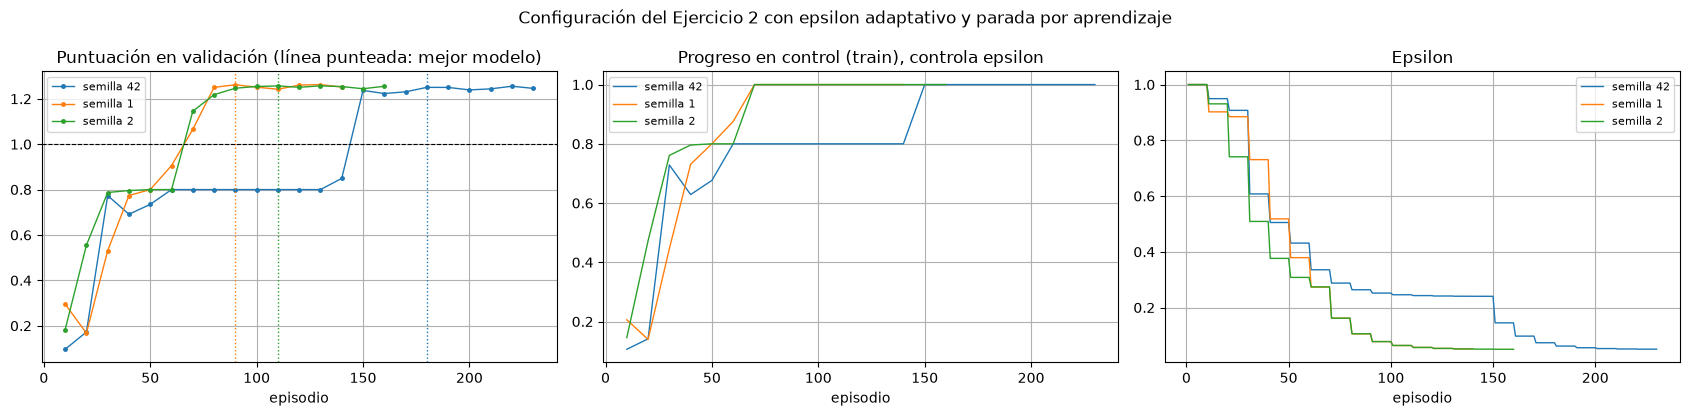

In [15]:
MAX_EPISODES = 400
good_runs, good_rows = {}, []
for seed in (42, 1, 2):
    d = CKPT_ROOT / f"ej3_semilla_{seed}"
    shutil.rmtree(d, ignore_errors=True)
    ag, h, inf = train_agent_c({**CFG_EJ2, "seed": seed, "max_episodes": MAX_EPISODES, "early_stop": True, "ckpt_dir": d},
                               verbose=False)
    good_runs[f"semilla {seed}"] = (h, inf)
    sm = summarize_b(evaluate_agent_b(ag, "val", ENV_EJ2, n_episodes=100))
    good_rows.append({"semilla": seed, "episodios": inf["episodes"], "motivo de parada": inf["stop_reason"],
                      "mejor modelo (episodio)": inf["best_episode"], "puntuación val.": inf["best_score"],
                      "órdenes completas (%)": sm["órdenes completas (%)"],
                      "error de seguimiento (%)": sm["error de seguimiento (% de la orden)"],
                      "tiempo usado (%)": sm["tiempo usado (% del episodio)"], "segundos": inf["seconds"]})
    if seed == 42:
        agent_ej3_42 = ag
display(pd.DataFrame(good_rows).set_index("semilla").round(3))
plot_stopping(good_runs, "Configuración del Ejercicio 2 con epsilon adaptativo y parada por aprendizaje")

Las tres semillas paran por convergencia en 140, 160 y 230 episodios, en lugar de los 200 fijos del Ejercicio 3.
Las semillas 1 y 2 ahorran entrenamiento; la 42 necesita más de 200: el agente *greedy* sigue el calendario desde el
episodio 60, pero hasta el 150 deja el último título sin comprar (puntuación fija en 0.8, el límite para órdenes
incompletas). Con 200 episodios fijos habría llegado justo; con la parada se le da el tiempo que necesita y se
para 50 episodios después de su mejor modelo. Los tres agentes completan el 100 % de las órdenes de validación con
un error de seguimiento del 0.54-0.55 %, el mismo resultado que en el Ejercicio 3.

### 4.4 Prueba de estrés: hiperparámetros del Ejercicio 1

[NUEVO] La misma prueba que en el Ejercicio 3 (γ = 0.99, aprender cada 64 steps, buffer de 50 000), ahora sin
número fijo de episodios: tope de 1 000 y parada por aprendizaje.

Episodio   50 | retorno  -1636.0 | control: progreso 0.00, error 45.45 %, completas 100 % | val: 0.000 (mejor 0.000, ep. 10) | eps 1.000


Episodio  100 | retorno  -1901.1 | control: progreso 0.16, error  3.04 %, completas 100 % | val: 0.223 (mejor 0.223, ep. 100) | eps 0.895


Episodio  150 | retorno  -1320.4 | control: progreso 0.13, error  4.67 %, completas   0 % | val: 0.145 (mejor 0.250, ep. 110) | eps 0.872


Episodio  200 | retorno   -911.6 | control: progreso 0.20, error  3.16 %, completas   0 % | val: 0.289 (mejor 0.289, ep. 200) | eps 0.822


Episodio  250 | retorno   -496.7 | control: progreso 0.74, error  1.13 %, completas   0 % | val: 0.780 (mejor 0.780, ep. 250) | eps 0.393


Episodio  300 | retorno   -318.7 | control: progreso 0.77, error  1.06 %, completas   0 % | val: 0.792 (mejor 0.792, ep. 300) | eps 0.294


... (2 outputs left out)

Episodio  450 | retorno   -206.3 | control: progreso 0.80, error  0.64 %, completas   0 % | val: 0.800 (mejor 0.792, ep. 300) | eps 0.240


Episodio  500 | retorno   -207.3 | control: progreso 0.80, error  0.75 %, completas   0 % | val: 0.800 (mejor 0.792, ep. 300) | eps 0.240


Episodio  550 | retorno   -219.7 | control: progreso 0.80, error  0.63 %, completas   0 % | val: 0.800 (mejor 0.792, ep. 300) | eps 0.240


Episodio  600 | retorno   -203.5 | control: progreso 0.80, error  0.62 %, completas   0 % | val: 0.800 (mejor 0.792, ep. 300) | eps 0.240
Fin: estancado tras 600 episodios (356 s). Mejor modelo: episodio 300, puntuación de validación 0.792


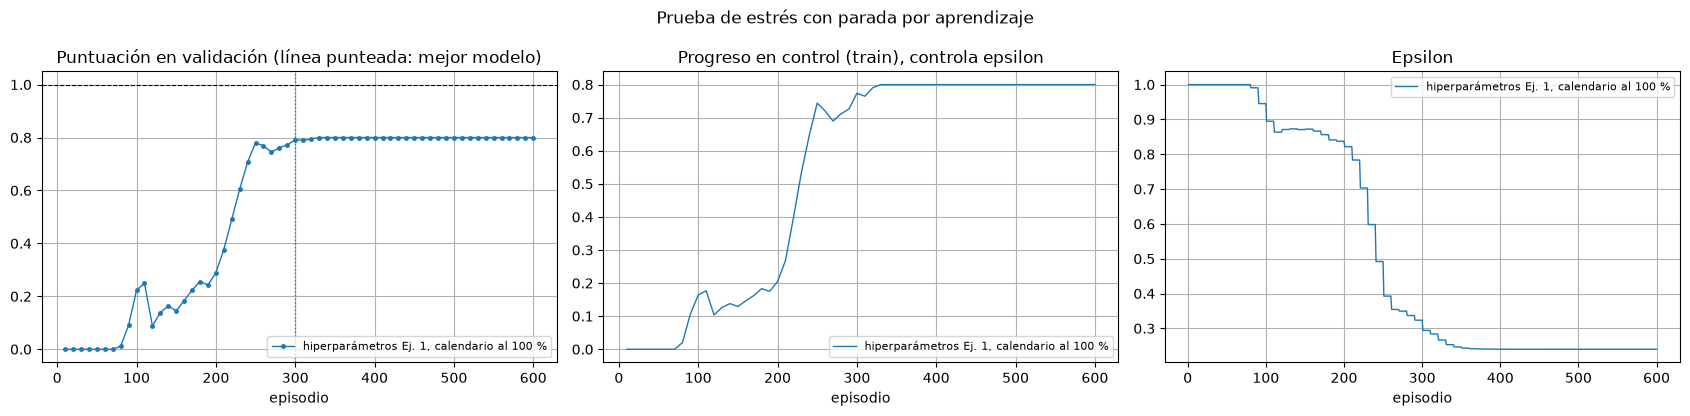

,mejor modelo guardado
órdenes completas (%),0.00
volumen pendiente medio (títulos),1.00
tiempo usado (% del episodio),100.00
"tiempo usado, mín. (%)",100.00
"tiempo usado, máx. (%)",100.00
error de seguimiento (% de la orden),1.16
slippage vs VWAP (bps),1.90
retorno medio,-274.94


In [16]:
CFG_EJ1 = dict(nepisodes=300, gamma=0.99, alpha=1e-3, buffer_size=50_000, batch_size=64,
               hidden_neurons=32, learn_after=64, update_target_mult=10)
d = CKPT_ROOT / "ej1_estres"
shutil.rmtree(d, ignore_errors=True)
ag_st, h_st, inf_st = train_agent_c({**CFG_EJ1, "max_episodes": 1000, "early_stop": True, "ckpt_dir": d}, n_log=50)
stress_runs = {"hiperparámetros Ej. 1, calendario al 100 %": (h_st, inf_st)}
plot_stopping(stress_runs, "Prueba de estrés con parada por aprendizaje")
display(summarize_b(evaluate_agent_b(ag_st, "val", ENV_EJ2, n_episodes=100)).to_frame("mejor modelo guardado").round(2))

Con estos hiperparámetros el agente acaba siguiendo bien el calendario (error del 0.6 % en control), pero desde el
episodio 300 deja siempre el último título sin comprar y no sale de ahí. La parada lo detecta: 30 mediciones sin
mejora y se detiene por «estancado» en el episodio 600, en lugar de llegar al tope de 1 000. Más episodios no habrían
resuelto el problema; hace falta cambiar algo del diseño o de los hiperparámetros. En 5.5 se ve que el entorno de la
Idea B lo resuelve.

### 4.5 Recuperar un modelo guardado

[NUEVO] Se crea un agente nuevo, se cargan los pesos de `best.pkl` (semilla 42 de 4.3) y se evalúa en *test*. Tiene
que tomar las mismas decisiones que el agente que devolvió el entrenamiento.

In [17]:
best_path = CKPT_ROOT / "ej3_semilla_42" / "best.pkl"
agent_disk, ck = load_best_agent(best_path)
print(f"{best_path.relative_to(REPO_ROOT)}: episodio {ck['episode'] + 1}, puntuación de validación {ck['val_score']:.3f}")
df_disk = evaluate_agent_b(agent_disk, "test", ENV_EJ2, n_episodes=100)
df_mem = evaluate_agent_b(agent_ej3_42, "test", ENV_EJ2, n_episodes=100)
print("Mismas decisiones que el agente devuelto por el entrenamiento:",
      np.array_equal(df_disk.sum_reward.values, df_mem.sum_reward.values))
display(summarize_b(df_disk).to_frame("agente cargado de best.pkl (test, 100 episodios)").round(2))

Ejercicio_4\checkpoints\ej3_semilla_42\best.pkl: episodio 180, puntuación de validación 1.251


Mismas decisiones que el agente devuelto por el entrenamiento: True


,"agente cargado de best.pkl (test, 100 episodios)"
órdenes completas (%),100.00
volumen pendiente medio (títulos),0.00
tiempo usado (% del episodio),99.22
"tiempo usado, mín. (%)",98.77
"tiempo usado, máx. (%)",99.49
error de seguimiento (% de la orden),0.55
slippage vs VWAP (bps),1.45
retorno medio,-129.61


---
## 5. Idea B: calibración y resultados

### 5.1 Calibración de λ y del arranque retrasado

Según la programación dinámica (3.3), `λ` no cambia la política óptima. Solo puede influir en el aprendizaje: en la
escala de los Q-valores (un `λ` grande hace que algunos valores sean muy negativos, el mismo problema que el
Ejercicio 2 encontró con γ = 0.99) y en lo que aprende la red en estados poco visitados. Por eso se calibra
entrenando: `λ ∈ {0, 10, 100, 1000}`, dos semillas, parada por aprendizaje (sección 4) y evaluación sobre 100
episodios de validación.

Además de los criterios habituales se mide el comportamiento con **arranque retrasado**: el agente no puede operar
durante el 30-85 % inicial del episodio (por ejemplo, un corte de conexión) y luego tiene que recuperar el retraso.
El margen del 10 % solo sirve si el agente sabe recuperarse. Estos estados casi no aparecen en el entrenamiento: el
agente siempre compra en el step 0 (regla heredada de `DDQNAgent.act`) y la exploración sigue más o menos el
calendario. Por eso se prueba también una opción de entrenamiento: en un 30 % de los episodios las primeras
`U(0.1, 0.85)·B` acciones se fuerzan a «no comprar». Es la idea de los *exploring starts*: empezar episodios en
estados que de otro modo no se visitarían. Como DQN aprende *off-policy*, puede aprender de esas transiciones
aunque no las haya elegido el agente.

[NUEVO] Calibración (16 entrenamientos, unos 45 minutos).

In [18]:
RHO = 0.9
DELAY_EVAL = (0.3, 0.85)       # arranque retrasado en la evaluación: sin operar durante el 30-85 % inicial
calib_rows = []
for delay_prob in (0.0, 0.3):
    for lam in (0, 10, 100, 1000):
        for seed in (42, 1):
            kw = dict(target_frac=RHO, pending_penalty=lam)
            ag, h, inf = train_agent_c({**CFG_EJ2, **kw, "seed": seed, "max_episodes": 400, "early_stop": True,
                                        "delay_prob": delay_prob}, verbose=False)
            ev = evaluate_agent_b(ag, "val", kw)
            ev_d = evaluate_agent_b(ag, "val", kw, delay=DELAY_EVAL)
            calib_rows.append({
                "arranques retrasados en train": delay_prob, "lambda": lam, "semilla": seed,
                "episodios": inf["episodes"], "parada": inf["stop_reason"],
                "completas (%)": (ev.exec_frac >= 1).mean() * 100, "tiempo usado (%)": ev.time_frac.mean() * 100,
                "error (%)": ev.mae_pct.mean(),
                "completas con arranque retrasado (%)": (ev_d.exec_frac >= 1).mean() * 100,
                "pendiente con arranque retrasado": ev_d.pending.mean(),
                "pérdida máxima": h.loss.max(), "segundos": inf["seconds"]})
            print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in calib_rows[-1].items()})
calib_df = pd.DataFrame(calib_rows)
display(calib_df.set_index(["arranques retrasados en train", "lambda", "semilla"]).round(2))

{'arranques retrasados en train': 0.0, 'lambda': 0, 'semilla': 42, 'episodios': 160, 'parada': 'convergido', 'completas (%)': np.float64(100.0), 'tiempo usado (%)': np.float64(89.58), 'error (%)': np.float64(0.54), 'completas con arranque retrasado (%)': np.float64(100.0), 'pendiente con arranque retrasado': np.float64(0.0), 'pérdida máxima': np.float64(215.61), 'segundos': 79.14}


{'arranques retrasados en train': 0.0, 'lambda': 0, 'semilla': 1, 'episodios': 150, 'parada': 'convergido', 'completas (%)': np.float64(100.0), 'tiempo usado (%)': np.float64(89.52), 'error (%)': np.float64(0.54), 'completas con arranque retrasado (%)': np.float64(100.0), 'pendiente con arranque retrasado': np.float64(0.0), 'pérdida máxima': np.float64(398.24), 'segundos': 103.13}


{'arranques retrasados en train': 0.0, 'lambda': 10, 'semilla': 42, 'episodios': 180, 'parada': 'convergido', 'completas (%)': np.float64(100.0), 'tiempo usado (%)': np.float64(89.27), 'error (%)': np.float64(0.54), 'completas con arranque retrasado (%)': np.float64(0.0), 'pendiente con arranque retrasado': np.float64(49.04), 'pérdida máxima': np.float64(94.21), 'segundos': 159.31}


{'arranques retrasados en train': 0.0, 'lambda': 10, 'semilla': 1, 'episodios': 150, 'parada': 'convergido', 'completas (%)': np.float64(100.0), 'tiempo usado (%)': np.float64(89.37), 'error (%)': np.float64(0.54), 'completas con arranque retrasado (%)': np.float64(100.0), 'pendiente con arranque retrasado': np.float64(0.0), 'pérdida máxima': np.float64(116.37), 'segundos': 135.05}


{'arranques retrasados en train': 0.0, 'lambda': 100, 'semilla': 42, 'episodios': 140, 'parada': 'convergido', 'completas (%)': np.float64(100.0), 'tiempo usado (%)': np.float64(89.23), 'error (%)': np.float64(0.55), 'completas con arranque retrasado (%)': np.float64(100.0), 'pendiente con arranque retrasado': np.float64(0.0), 'pérdida máxima': np.float64(354.21), 'segundos': 110.86}


{'arranques retrasados en train': 0.0, 'lambda': 100, 'semilla': 1, 'episodios': 100, 'parada': 'convergido', 'completas (%)': np.float64(100.0), 'tiempo usado (%)': np.float64(89.07), 'error (%)': np.float64(0.55), 'completas con arranque retrasado (%)': np.float64(100.0), 'pendiente con arranque retrasado': np.float64(0.0), 'pérdida máxima': np.float64(289.03), 'segundos': 86.07}


... (7 outputs left out)

{'arranques retrasados en train': 0.3, 'lambda': 100, 'semilla': 1, 'episodios': 210, 'parada': 'convergido', 'completas (%)': np.float64(100.0), 'tiempo usado (%)': np.float64(89.0), 'error (%)': np.float64(0.54), 'completas con arranque retrasado (%)': np.float64(100.0), 'pendiente con arranque retrasado': np.float64(0.0), 'pérdida máxima': np.float64(5814.62), 'segundos': 167.16}


{'arranques retrasados en train': 0.3, 'lambda': 1000, 'semilla': 42, 'episodios': 310, 'parada': 'convergido', 'completas (%)': np.float64(100.0), 'tiempo usado (%)': np.float64(88.55), 'error (%)': np.float64(0.55), 'completas con arranque retrasado (%)': np.float64(100.0), 'pendiente con arranque retrasado': np.float64(0.0), 'pérdida máxima': np.float64(568495.5), 'segundos': 247.96}


{'arranques retrasados en train': 0.3, 'lambda': 1000, 'semilla': 1, 'episodios': 400, 'parada': 'tope de episodios', 'completas (%)': np.float64(100.0), 'tiempo usado (%)': np.float64(87.65), 'error (%)': np.float64(0.83), 'completas con arranque retrasado (%)': np.float64(100.0), 'pendiente con arranque retrasado': np.float64(0.0), 'pérdida máxima': np.float64(501023.92), 'segundos': 284.29}


episodios             parada  \
arranques retrasados en train lambda semilla                                 
0.0                           0      42             160         convergido   
                                     1              150         convergido   
                              10     42             180         convergido   
                                     1              150         convergido   
                              100    42             140         convergido   
                                     1              100         convergido   
                              1000   42             210         convergido   
                                     1              110         convergido   
0.3                           0      42             160         convergido   
                                     1              270         convergido   
                              10     42             220         convergido   
                                     1              230         convergido   
                              100    42             220         convergido   
                                     1              210         convergido   
                              1000   42             310         convergido   
                                     1              400  tope de episodios   

                                              completas (%)  tiempo usado (%)  \
arranques retrasados en train lambda semilla                                    
0.0                           0      42               100.0             89.58   
                                     1                100.0             89.52   
                              10     42               100.0             89.27   
                                     1                100.0             89.37   
                              100    42               100.0             89.23   
                                     1                100.0             89.07   
                              1000   42               100.0             88.76   
                                     1                100.0             88.87   
0.3                           0      42               100.0             89.26   
                                     1                100.0             89.76   
                              10     42               100.0             89.23   
                                     1                100.0             89.37   
                              100    42               100.0             89.25   
                                     1                100.0             89.00   
                              1000   42               100.0             88.55   
                                     1                100.0             87.65   

                                              error (%)  \
arranques retrasados en train lambda semilla              
0.0                           0      42            0.54   
                                     1             0.54   
                              10     42            0.54   
                                     1             0.54   
                              100    42            0.55   
                                     1             0.55   
                              1000   42            0.55   
                                     1             0.60   
0.3                           0      42            0.54   
                                     1             0.56   
                              10     42            0.55   
                                     1             0.55   
                              100    42            0.59   
                                     1             0.54   
                              1000   42            0.55   
                                     1             0.83   

                                              completas con arranque retrasado (%)  \
arranques retrasados en train lam

**Lectura y decisión.**

* `λ` entre 0 y 100 da el mismo resultado: 100 % de órdenes completas, ≈ 89.3 % del tiempo y error del 0.54-0.59 %.
* `λ = 1000` dispara la pérdida máxima (de 10²-10⁴ a 3·10⁴-6·10⁵), tarda más en converger y en un caso llega
  al tope de 400 episodios con un error del 0.83 %. Es el problema de escala de los valores ya visto en el
  Ejercicio 2.
* Sin arranques retrasados en el entrenamiento, uno de los ocho agentes (`λ = 10`, semilla 42) no compra nada si
  empieza retrasado: deja la orden entera pendiente aunque tiene tiempo de sobra para completarla. Con arranques
  retrasados, los ocho agentes completan el 100 % de las órdenes también en esa prueba. El coste es entrenar algo
  más (160-270 episodios frente a 100-180, sin contar `λ = 1000`).

Se elige `λ = 10`, la penalización explícita más pequeña de las probadas: no cambia la escala de los valores, y
dejar volumen pendiente queda castigado aunque el episodio acabe justo después de `T*`. Se eligen también los
arranques retrasados en el 30 % de los episodios.

In [19]:
LAMBDA = 10           # penalización por título pendiente si el episodio acaba por tiempo
DELAY_PROB = 0.3      # fracción de episodios de entrenamiento con arranque retrasado

### 5.2 Agente final

[NUEVO] Configuración del Ejercicio 2 con el entorno de la Idea B (`ρ = 0.9`, `λ` y arranque retrasado elegidos en
5.1), ε adaptativo y parada por aprendizaje. Se evalúa el mejor modelo guardado en *train*, *validation* y *test*,
sobre los mismos episodios, junto con:

* el agente del Ejercicio 3 (semilla 42 de 4.3), en su propio entorno con el calendario al 100 %;
* el TWAP con el calendario al 90 %;
* la regla óptima `lag > 1/2` (3.3).

Episodio   20 | retorno  -4450.5 | control: progreso 0.25, error  3.79 %, completas   0 % | val: 0.211 (mejor 0.211, ep. 20) | eps 0.881


Episodio   40 | retorno  -1762.5 | control: progreso 0.76, error  1.10 %, completas   0 % | val: 0.734 (mejor 0.734, ep. 40) | eps 0.522


Episodio   60 | retorno  -1848.4 | control: progreso 0.78, error  1.00 %, completas   0 % | val: 0.760 (mejor 0.761, ep. 50) | eps 0.322


Episodio   80 | retorno  -2899.7 | control: progreso 0.91, error  0.85 %, completas 100 % | val: 0.906 (mejor 0.906, ep. 80) | eps 0.210


Episodio  100 | retorno   -816.3 | control: progreso 1.00, error  0.69 %, completas 100 % | val: 1.061 (mejor 1.061, ep. 100) | eps 0.094


Episodio  120 | retorno  -1500.4 | control: progreso 1.00, error  0.66 %, completas 100 % | val: 1.084 (mejor 1.084, ep. 120) | eps 0.074


Episodio  140 | retorno  -1673.8 | control: progreso 1.00, error  0.54 %, completas 100 % | val: 1.190 (mejor 1.190, ep. 140) | eps 0.057


Episodio  160 | retorno  -1806.6 | control: progreso 1.00, error  0.51 %, completas 100 % | val: 1.222 (mejor 1.222, ep. 160) | eps 0.052


Episodio  180 | retorno  -1927.7 | control: progreso 1.00, error  0.59 %, completas 100 % | val: 1.141 (mejor 1.238, ep. 170) | eps 0.050


Episodio  200 | retorno   -136.8 | control: progreso 1.00, error  0.50 %, completas 100 % | val: 1.226 (mejor 1.238, ep. 170) | eps 0.050


Episodio  220 | retorno  -1419.3 | control: progreso 1.00, error  0.55 %, completas 100 % | val: 1.189 (mejor 1.238, ep. 170) | eps 0.050
Fin: convergido tras 220 episodios (196 s). Mejor modelo: episodio 170, puntuación de validación 1.238


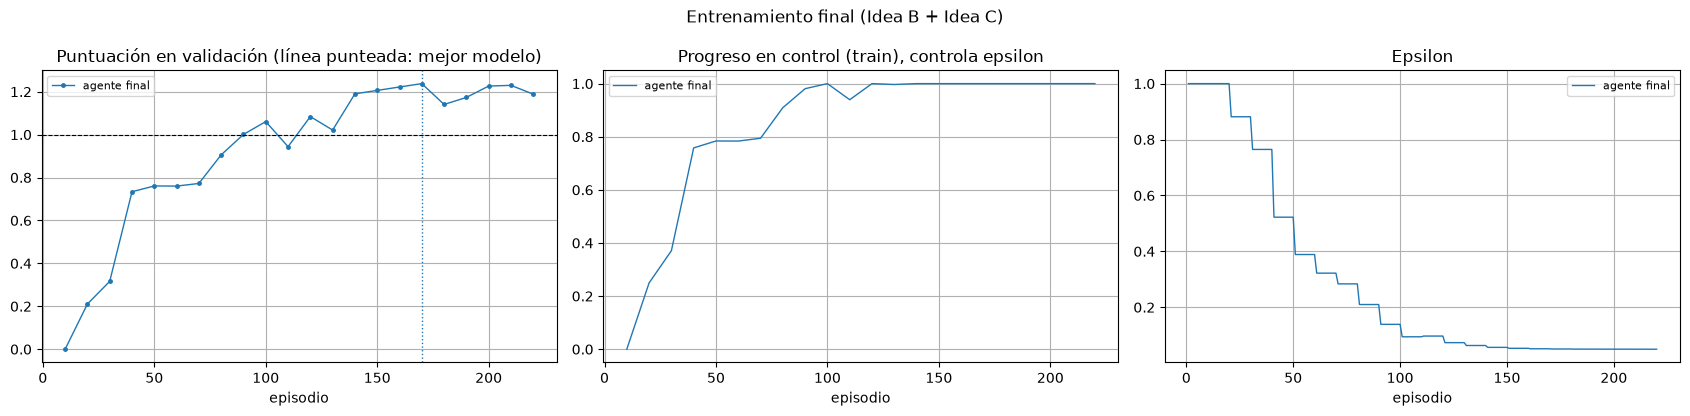

train: 200 episodios


,DQN Idea B,"DQN Ejercicio 3 (en su entorno, calendario al 100 %)",TWAP al 90 %,regla lag > 1/2
órdenes completas (%),100.00,100.00,100.00,100.00
volumen pendiente medio (títulos),0.00,0.00,0.00,0.00
tiempo usado (% del episodio),89.23,99.23,88.43,89.16
"tiempo usado, mín. (%)",88.73,98.77,87.50,88.64
"tiempo usado, máx. (%)",89.56,99.49,89.06,89.53
error de seguimiento (% de la orden),0.55,0.55,0.84,0.52
slippage vs VWAP (bps),2.80,2.81,2.80,2.79
retorno medio,-116.07,-129.33,-179.32,-111.37


val: 100 episodios


,DQN Idea B,"DQN Ejercicio 3 (en su entorno, calendario al 100 %)",TWAP al 90 %,regla lag > 1/2
órdenes completas (%),100.00,100.00,100.00,100.00
volumen pendiente medio (títulos),0.00,0.00,0.00,0.00
tiempo usado (% del episodio),89.23,99.22,88.42,89.16
"tiempo usado, mín. (%)",88.81,98.77,87.59,88.64
"tiempo usado, máx. (%)",89.56,99.49,89.06,89.44
error de seguimiento (% de la orden),0.55,0.55,0.85,0.53
slippage vs VWAP (bps),1.83,1.93,1.81,1.82
retorno medio,-116.30,-129.61,-180.26,-111.57


test: 100 episodios


,DQN Idea B,"DQN Ejercicio 3 (en su entorno, calendario al 100 %)",TWAP al 90 %,regla lag > 1/2
órdenes completas (%),100.00,100.00,100.00,100.00
volumen pendiente medio (títulos),0.00,0.00,0.00,0.00
tiempo usado (% del episodio),89.23,99.22,88.42,89.16
"tiempo usado, mín. (%)",88.81,98.77,87.59,88.64
"tiempo usado, máx. (%)",89.56,99.49,89.06,89.44
error de seguimiento (% de la orden),0.55,0.55,0.85,0.53
slippage vs VWAP (bps),1.44,1.45,1.45,1.43
retorno medio,-116.30,-129.61,-180.26,-111.57


In [20]:
ENV_B = dict(target_frac=RHO, pending_penalty=LAMBDA)
CFG_FINAL = {**CFG_EJ2, **ENV_B, "delay_prob": DELAY_PROB, "max_episodes": 400, "early_stop": True,
             "ckpt_dir": CKPT_ROOT / "final_idea_b"}
shutil.rmtree(CKPT_ROOT / "final_idea_b", ignore_errors=True)
agent_b, hist_b, info_b = train_agent_c(CFG_FINAL)
plot_stopping({"agente final": (hist_b, info_b)}, "Entrenamiento final (Idea B + Idea C)")

# Evaluación greedy del mejor modelo frente a las referencias, en los tres conjuntos y con los mismos episodios
N_FINAL = {"train": 200, "val": 100, "test": 100}
final_tables = {}
for split, n in N_FINAL.items():
    env_s = BestExecutionEnvB(dict_[split], 60, **ENV_B)
    res = {
        "DQN Idea B": evaluate_agent_b(agent_b, split, ENV_B, n_episodes=n),
        "DQN Ejercicio 3 (en su entorno, calendario al 100 %)": evaluate_agent_b(agent_ej3_42, split, ENV_EJ2, n_episodes=n),
        "TWAP al 90 %": run_policy_b(env_s, TWAPB(env_s).act, n, seed0=30_000),
        "regla lag > 1/2": run_policy_b(env_s, lambda s, e=env_s: int(s[2] * e.LAG_CLIP > 0.5), n, seed0=30_000),
    }
    final_tables[split] = res
    print(f"{split}: {n} episodios")
    display(pd.DataFrame({k: summarize_b(v) for k, v in res.items()}).round(2))

El entrenamiento para por convergencia en el episodio 220 y el mejor modelo es el del 170. El retorno de
entrenamiento que se imprime es ruidoso porque incluye los episodios con arranque retrasado, que tienen retornos
muy negativos por construcción. Por eso la parada se decide con la evaluación *greedy* y no con ese retorno.

En los tres conjuntos, el agente completa el 100 % de las órdenes, sin volumen pendiente, usando el 89.2 % del
episodio (entre el 88.7 y el 89.6 %). Su error respecto al calendario al 90 % es del 0.55 %, casi el de la regla
óptima (0.52 %) y mejor que el del TWAP al 90 % (0.84 %). El agente del Ejercicio 3 sigue usando el 99.2 %. El
*slippage* es prácticamente igual en todas las políticas: terminar antes no mejora ni empeora el precio, solo deja
margen.

En *validation* y *test* los criterios de calendario salen idénticos porque se usan las mismas semillas de episodio
(mismas `B`, `C` y hora) y la política no depende del precio; lo que cambia entre conjuntos es el *slippage*.

### 5.3 Gráficos

[NUEVO] Figura estándar del repositorio (`plot_results`) en dos episodios de *train*. Después, el volumen acumulado
frente al calendario al 90 % en tres episodios distintos (agente de la Idea B y agente del Ejercicio 3) y la
distribución del momento en que se completa la orden en *test*.

2018-03-22 14:35 · B = 447, C = 36 · ejecutado 100 % en el 89.0 % del tiempo · error 0.73 %


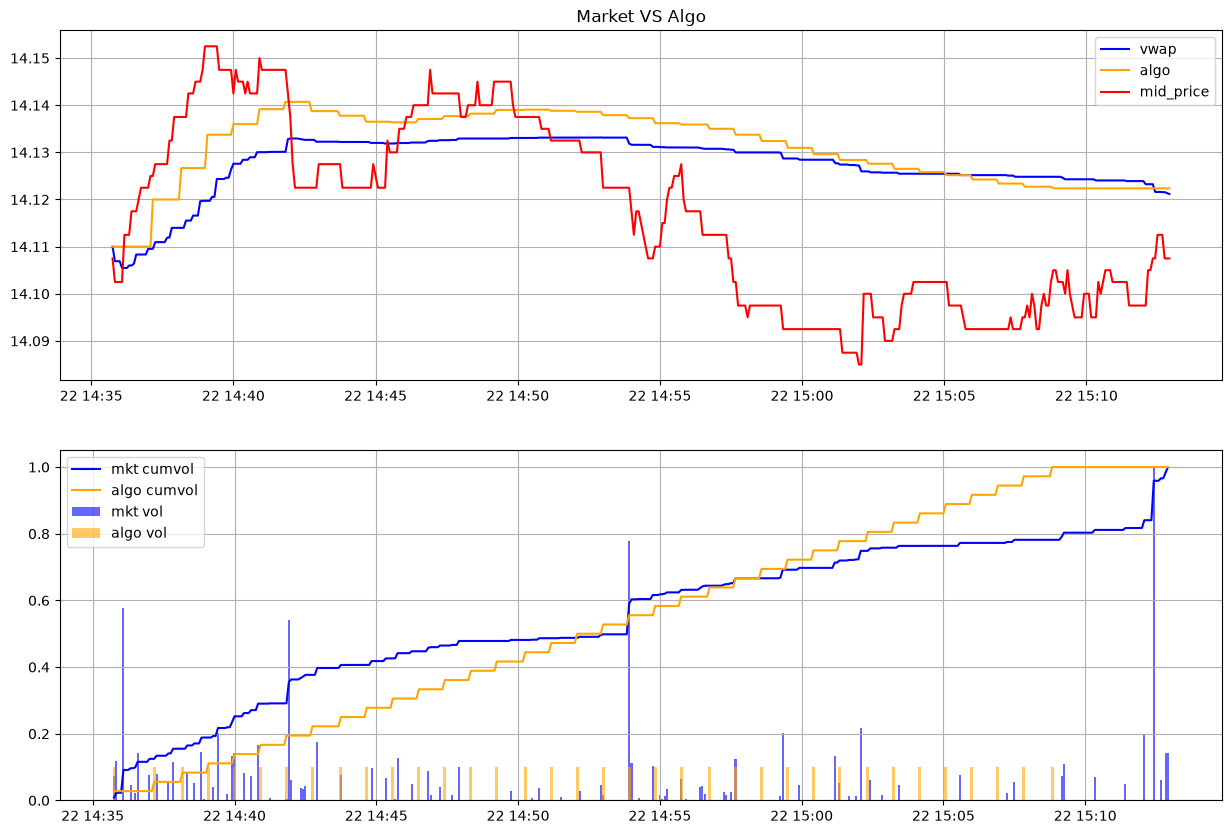

2018-01-24 16:13 · B = 594, C = 65 · ejecutado 100 % en el 89.4 % del tiempo · error 0.40 %


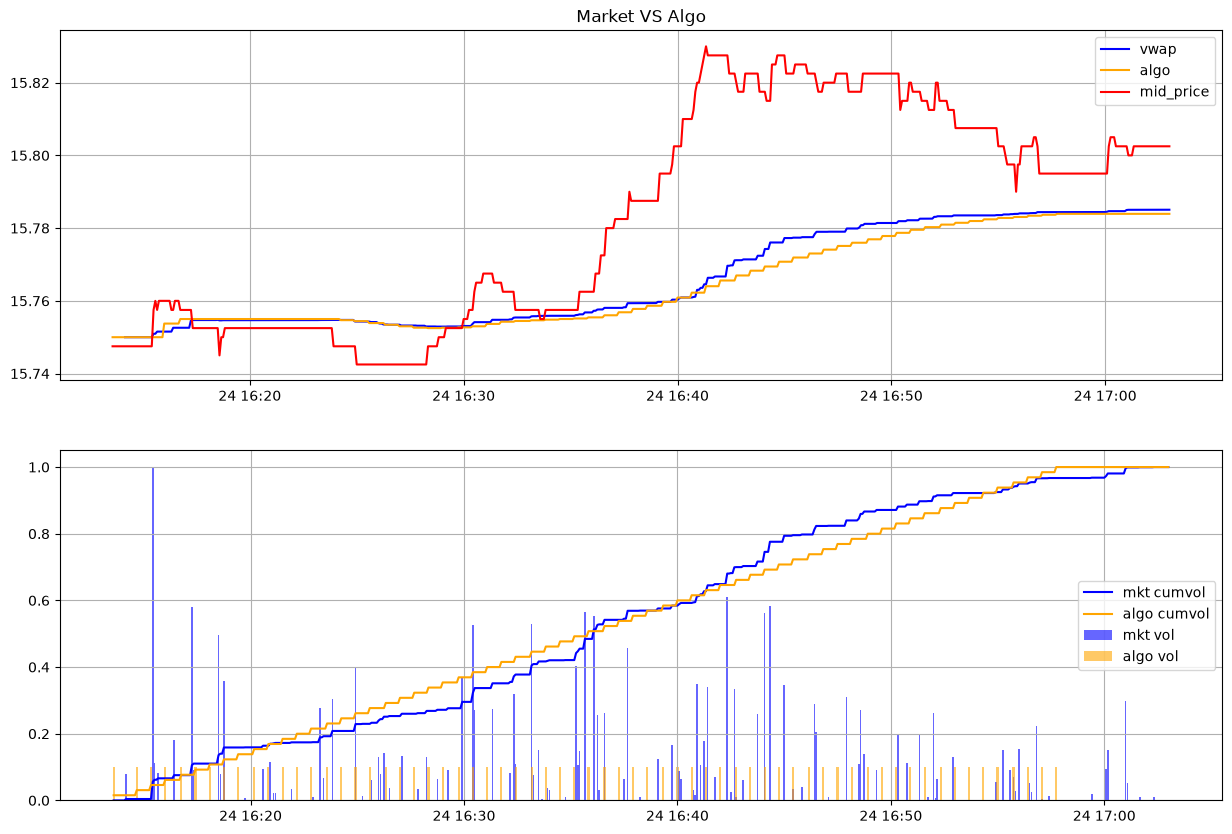

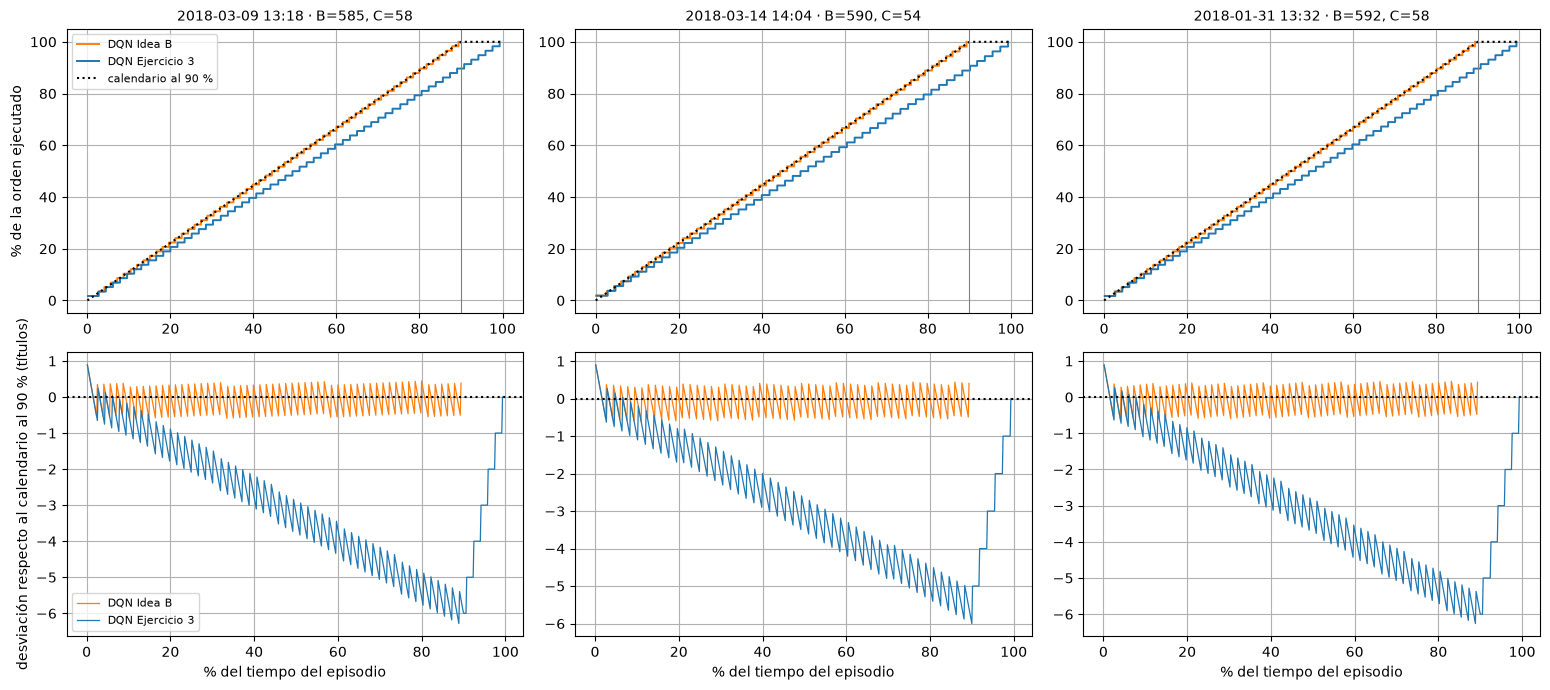

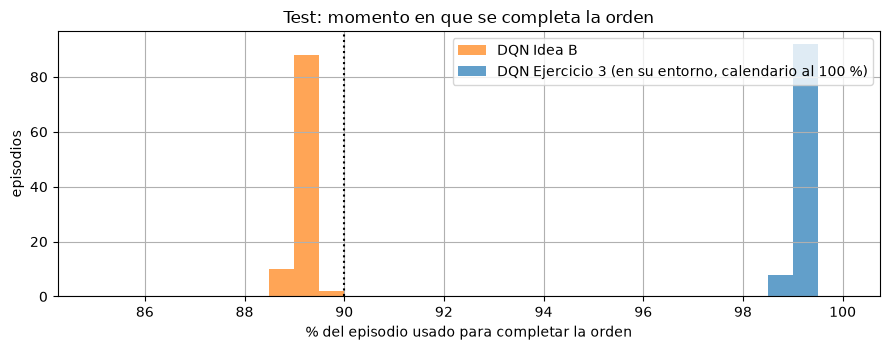

In [21]:
def plot_gallery_b(named_agents, seeds, split="train"):
    """named_agents: {nombre: (agente, color, env_kw)}. Cada agente juega en su propio entorno; el volumen acumulado y la
    desviación se dibujan respecto al calendario al 90 %."""
    fig, ax = plt.subplots(2, len(seeds), figsize=(5.2 * len(seeds), 7), squeeze=False)
    for j, seed in enumerate(seeds):
        for name, (ag, color, env_kw) in named_agents.items():
            env = BestExecutionEnvB(dict_[split], 60, **env_kw)
            ag.set_trainable(False); ag.env = env
            np.random.seed(seed)
            s, done = env.reset(), False
            while not done:
                s, r, done, _ = env.step(ag.act(s))
            B, C, n = env.episode_bins, env.vol_care, env.state_pos
            x = np.arange(1, n + 1) / B * 100
            ejec = np.cumsum(env.vol_hist)
            ax[0, j].step(x, ejec / C * 100, where="post", color=color, lw=1.4, label=name)
            ax[1, j].plot(x, ejec - np.minimum(C * np.arange(1, n + 1) / (RHO * B), C), color=color, lw=0.9, label=name)
        xs = np.linspace(0, 100, 201)
        ax[0, j].plot(xs, np.minimum(xs / RHO, 100), "k:", label="calendario al 90 %")
        ax[0, j].axvline(RHO * 100, color="gray", lw=0.8)
        ax[0, j].set_title(f"{env.episode.index[0]:%Y-%m-%d %H:%M} · B={B}, C={C}", fontsize=10)
        ax[1, j].axhline(0, color="k", ls=":"); ax[1, j].set_xlabel("% del tiempo del episodio")
    ax[0, 0].set_ylabel("% de la orden ejecutado"); ax[1, 0].set_ylabel("desviación respecto al calendario al 90 % (títulos)")
    ax[0, 0].legend(fontsize=8); ax[1, 0].legend(fontsize=8)
    for a_ in ax.ravel():
        a_.grid(True)
    plt.tight_layout(); plt.show()


# Figura estándar del repositorio (mismo tipo que la imagen de referencia del enunciado), dos episodios de train
img_env = BestExecutionEnvB(dict_["train"], 60, **ENV_B)
agent_b.set_trainable(False); agent_b.env = img_env
for seed in (10_001, 10_007):
    np.random.seed(seed)
    s, done = img_env.reset(), False
    while not done:
        s, r, done, _ = img_env.step(agent_b.act(s))
    m = episode_metrics_b(img_env)
    print(f"{img_env.episode.index[0]:%Y-%m-%d %H:%M} · B = {m['bins']}, C = {m['vol_care']} · ejecutado "
          f"{m['exec_frac'] * 100:.0f} % en el {m['time_frac'] * 100:.1f} % del tiempo · error {m['mae_pct']:.2f} %")
    plot_results(img_env); plt.show()

plot_gallery_b({"DQN Idea B": (agent_b, "tab:orange", ENV_B), "DQN Ejercicio 3": (agent_ej3_42, "tab:blue", ENV_EJ2)},
               seeds=[20_002, 20_005, 20_011])

# Tiempo usado por episodio (test)
fig, ax = plt.subplots(figsize=(9, 3.6))
for name, color in (("DQN Idea B", "tab:orange"), ("DQN Ejercicio 3 (en su entorno, calendario al 100 %)", "tab:blue")):
    ax.hist(final_tables["test"][name].time_frac * 100, bins=np.arange(85, 100.5, 0.5), color=color, alpha=0.7, label=name)
ax.axvline(RHO * 100, color="k", ls=":"); ax.set_xlabel("% del episodio usado para completar la orden")
ax.set_ylabel("episodios"); ax.set_title("Test: momento en que se completa la orden"); ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

En la figura estándar el volumen acumulado del algoritmo es una escalera regular que llega al 100 % hacia el 89 % del
episodio; el resto queda libre. En la galería, la desviación del agente de la Idea B oscila entre −0.5 y +0.5
títulos alrededor del calendario al 90 %. El agente del Ejercicio 3 se va retrasando respecto a ese calendario
porque sigue el suyo, que termina al 100 %. El histograma confirma que en *test* todos los episodios terminan entre
el 88.8 y el 89.6 %.

### 5.4 Arranque retrasado

[NUEVO] 100 episodios de *test* en los que el agente no puede operar durante el 30-85 % inicial.

,DQN Idea B,"DQN Ejercicio 3 (en su entorno, calendario al 100 %)",TWAP al 90 %
órdenes completas (%),100.00,0.00,100.00
volumen pendiente medio (títulos),0.00,49.04,0.00
tiempo usado (% del episodio),89.40,100.00,88.66
"tiempo usado, mín. (%)",88.81,100.00,87.59
"tiempo usado, máx. (%)",93.51,100.00,93.51
error de seguimiento (% de la orden),24.87,50.10,25.14
slippage vs VWAP (bps),1.21,NaN,1.20
retorno medio,-5529.72,-12313.50,-5548.11


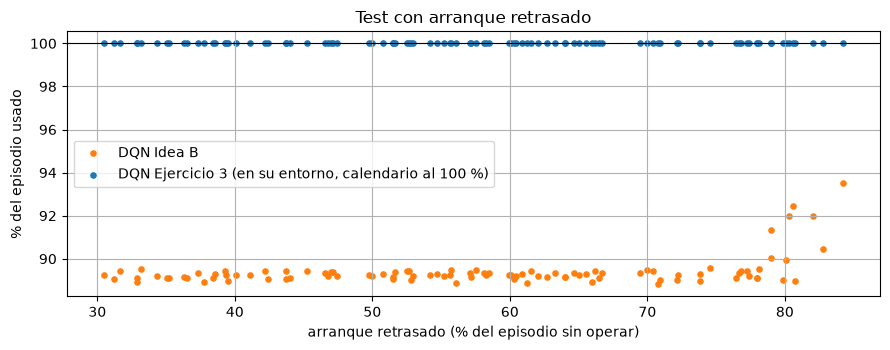

In [22]:
rob = {}
env_t = BestExecutionEnvB(dict_["test"], 60, **ENV_B)
rob["DQN Idea B"] = evaluate_agent_b(agent_b, "test", ENV_B, delay=DELAY_EVAL)
rob["DQN Ejercicio 3 (en su entorno, calendario al 100 %)"] = evaluate_agent_b(agent_ej3_42, "test", ENV_EJ2, delay=DELAY_EVAL)
rob["TWAP al 90 %"] = run_policy_b(env_t, TWAPB(env_t).act, 100, seed0=30_000, delay=DELAY_EVAL)
display(pd.DataFrame({k: summarize_b(v) for k, v in rob.items()}).round(2))

fig, ax = plt.subplots(figsize=(9, 3.6))
for name, color in (("DQN Idea B", "tab:orange"), ("DQN Ejercicio 3 (en su entorno, calendario al 100 %)", "tab:blue")):
    ax.scatter(rob[name].delay * 100, rob[name].time_frac * 100, s=14, color=color, label=name)
ax.axhline(100, color="k", lw=0.8)
ax.set_xlabel("arranque retrasado (% del episodio sin operar)"); ax.set_ylabel("% del episodio usado")
ax.set_title("Test con arranque retrasado"); ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

El agente de la Idea B completa las 100 órdenes. Cuando el retraso es grande (más del ≈ 78 % del episodio) usa
parte del margen y termina entre el 90 y el 93.5 %, igual que el TWAP al 90 %. El error de seguimiento alto (25 %)
es inevitable: durante el retraso no se puede operar.

El agente del Ejercicio 3 no completa ninguna: tras el retraso no vuelve a comprar y deja toda la orden pendiente,
aunque en todos los casos tenía tiempo para completarla. Es el mismo fallo que apareció en la calibración: nunca ha
visto estados con `vol_left = 1` pasado el inicio del episodio. Esto muestra que el margen solo sirve si el agente
ha aprendido a recuperarse, que es lo que aportan los arranques retrasados en el entrenamiento.

### 5.5 Hiperparámetros del Ejercicio 1 con el entorno de la Idea B

[NUEVO] La prueba de estrés de 4.4 repetida con el entorno de la Idea B. Sirve para ver si el margen ayuda con el
fallo del último título.

Episodio   50 | retorno  -4481.6 | control: progreso 0.00, error 44.84 %, completas 100 % | val: 0.000 (mejor 0.000, ep. 10) | eps 1.000


Episodio  100 | retorno  -4638.4 | control: progreso 0.00, error 44.84 %, completas 100 % | val: 0.000 (mejor 0.000, ep. 10) | eps 1.000


Episodio  150 | retorno  -5297.9 | control: progreso 0.83, error  0.64 %, completas 100 % | val: 0.820 (mejor 0.863, ep. 120) | eps 0.447


Episodio  200 | retorno  -3404.2 | control: progreso 0.93, error  0.89 %, completas 100 % | val: 0.940 (mejor 1.181, ep. 170) | eps 0.118


Episodio  250 | retorno  -1509.7 | control: progreso 0.67, error  1.59 %, completas 100 % | val: 0.626 (mejor 1.181, ep. 170) | eps 0.278


Episodio  300 | retorno  -1930.1 | control: progreso 0.60, error  1.85 %, completas 100 % | val: 0.532 (mejor 1.181, ep. 170) | eps 0.380


Episodio  350 | retorno  -1069.7 | control: progreso 0.63, error  1.71 %, completas 100 % | val: 0.567 (mejor 1.181, ep. 170) | eps 0.401


Episodio  400 | retorno  -1505.4 | control: progreso 0.73, error  1.34 %, completas 100 % | val: 0.694 (mejor 1.181, ep. 170) | eps 0.330


Episodio  450 | retorno  -1439.0 | control: progreso 0.95, error  0.83 %, completas 100 % | val: 0.969 (mejor 1.181, ep. 170) | eps 0.139


Fin: estancado tras 470 episodios (278 s). Mejor modelo: episodio 170, puntuación de validación 1.181


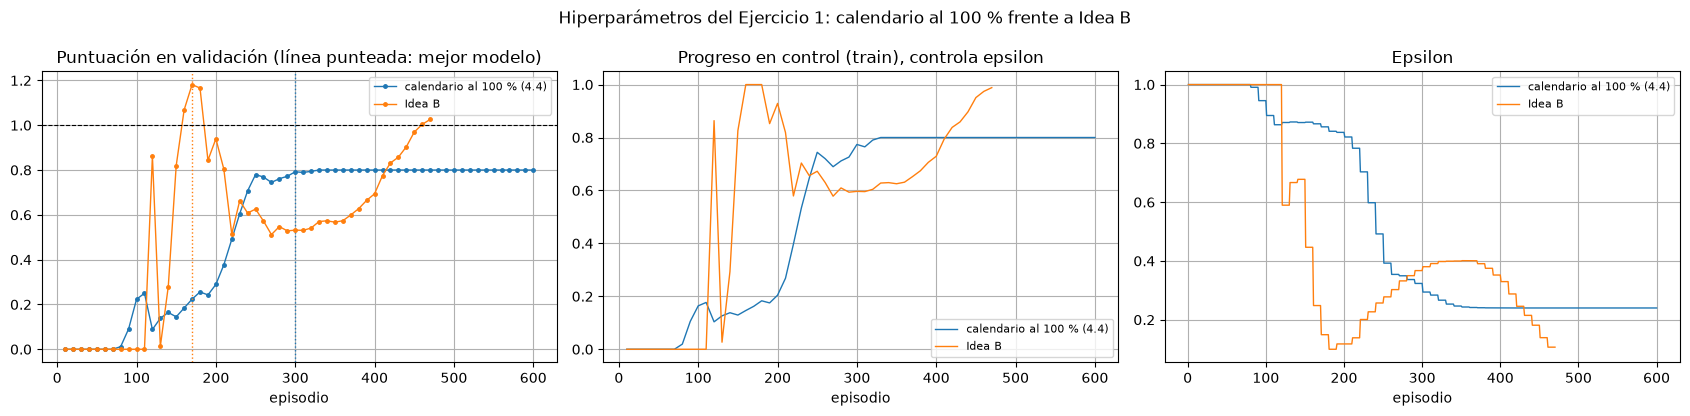

,calendario al 100 % (4.4),Idea B
órdenes completas (%),0.00,100.00
volumen pendiente medio (títulos),1.00,0.00
tiempo usado (% del episodio),100.00,88.93
"tiempo usado, mín. (%)",100.00,88.32
"tiempo usado, máx. (%)",100.00,89.32
error de seguimiento (% de la orden),1.16,0.61
slippage vs VWAP (bps),1.90,1.85
retorno medio,-274.94,-129.65


In [23]:
d = CKPT_ROOT / "ej1_estres_idea_b"
shutil.rmtree(d, ignore_errors=True)
ag_stb, h_stb, inf_stb = train_agent_c({**CFG_EJ1, **ENV_B, "delay_prob": DELAY_PROB, "max_episodes": 1000,
                                        "early_stop": True, "ckpt_dir": d}, n_log=50)
plot_stopping({"calendario al 100 % (4.4)": (h_st, inf_st), "Idea B": (h_stb, inf_stb)},
              "Hiperparámetros del Ejercicio 1: calendario al 100 % frente a Idea B")
display(pd.DataFrame({"calendario al 100 % (4.4)": summarize_b(evaluate_agent_b(ag_st, "val", ENV_EJ2)),
                      "Idea B": summarize_b(evaluate_agent_b(ag_stb, "val", ENV_B))}).round(2))

Con el entorno de la Idea B, los mismos hiperparámetros malos sí llegan a completar las órdenes. En el margen, cada
step sin comprar el último título cuesta un punto, en lugar de castigarse solo en el último step. El mejor modelo
(episodio 170) completa el 100 % de las órdenes de validación en el 88.9 % del tiempo, con un error del 0.61 %.

Después el entrenamiento empeora: la puntuación cae a ≈ 0.55 y ε vuelve a subir, como está previsto en el
controlador del Ejercicio 3. Cuando se para por «estancado» (episodio 470), el agente del último episodio es peor
que el del 170. Como se devuelve el mejor modelo guardado, no se pierde. Es el caso para el que se pensaron los
checkpoints de la Idea C.

Límite de la parada: en el episodio 470 la puntuación estaba subiendo otra vez (1.03), pero aún por debajo del
mejor modelo, y el criterio «estancado» la cortó. Con `patience_stuck` más grande se habría dejado seguir; aquí no
cambia el resultado porque se conserva el mejor modelo.

---
## 6. Conclusiones

**Idea B.** Para terminar hacia el 90 % basta con desplazar el calendario objetivo a `T* = 0.9·B`. La recompensa
sigue siendo una sola señal en títulos. La programación dinámica confirma, antes de entrenar, que el óptimo termina
en el ≈ 89 % y no deja volumen pendiente. El agente final lo reproduce en *train*, *validation* y *test*: 100 % de
órdenes completas, 89.2 % del tiempo (88.7-89.6 %) y un error respecto al calendario del 0.55 %, frente al 0.52 %
del óptimo. Lo que más pesa para no dejar volumen pendiente no es `λ`, sino:

1. el margen, que convierte el último título en un coste por step en lugar de un coste puntual (con los
   hiperparámetros del Ejercicio 1 se pasa de 0 % a 100 % de órdenes completas);
2. entrenar con arranques retrasados, para que el agente aprenda a recuperarse cuando va por detrás. Sin ello, el
   agente del Ejercicio 3 y uno de los de la calibración no vuelven a comprar tras un retraso.

`λ` no cambia el óptimo. Valores grandes perjudican el entrenamiento por la escala de los valores; se deja
`λ = 10`.

**Idea C.** La duración del entrenamiento la decide el aprendizaje: entre 140 y 230 episodios con una
configuración buena, y parada por «estancado» cuando la configuración no aprende. El agente que se devuelve es el
mejor según validación, no el último, lo que en 5.5 evita perder un buen modelo cuando el entrenamiento empeora.
El checkpoint completo permite reanudar un entrenamiento interrumpido con exactamente el mismo resultado.

**Limitaciones.**

* Los parámetros de la parada (`patience`, `patience_stuck`, `min_delta`, 16 episodios de validación) se han
  elegido con criterio, sin ajustarlos. En 5.5 `patience_stuck` cortó un entrenamiento que estaba mejorando otra vez.
* Dos semillas por configuración en la calibración: sirve para ver diferencias grandes, no pequeñas.
* `ρ = 0.9` está fijado por el enunciado. Como la última compra cae medio intervalo antes de `T*`, el agente
  termina en el ≈ 89 %; si se quisiera exactamente el 90 % habría que usar `ρ ≈ 0.9/(1 − 1/2C)`.
* Se mantienen las simplificaciones del taller: un solo activo, sin impacto de mercado ni costes.